# [GSE220059](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE220059)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2024-09-29
> - Modified: 2025-01-12

> **Notes:**
> - Potential sample annotation inconsistency was observed in GSE220059, as the polysome-seq samples cluster opposite to their reported group labels.

# 1. Experimental Design

> RNA binding protein PRRC2B mediates translation of specific proteins and regulates cell cycle progression.
> - Feng Jiang, Omar M Hedaya, EngSoon Khor, Jiangbin Wu, Matthew Auguste, Peng Yao, RNA binding protein PRRC2B mediates translation of specific mRNAs and regulates cell cycle progression, Nucleic Acids Research, Volume 51, Issue 11, 23 June 2023, Pages 5831–5846, https://doi.org/10.1093/nar/gkad322.
> - total RNA-seq & Polysome-seq
> - Illumina NovaSeq 6000, PE150
> - GRCh38

| Sample | Organism | Cell | Source | Treatment | Fraction | Replicate |
| - | - | - | - | - | - | - |
| Control | Homo sapiens | HEK293T | Human embryonic kidney | Control shRNA | Total RNA | rep1~3 |
| shPRRC2B | Homo sapiens | HEK293T | Human embryonic kidney | shPRRC2B | Total RNA | rep1~3 |
| Control | Homo sapiens | HEK293T | Human embryonic kidney | Control shRNA | Polysome RNA | rep1~3 |
| shPRRC2B | Homo sapiens | HEK293T | Human embryonic kidney | shPRRC2B | Polysome RNA | rep1~3 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [ ]:
data_dir <- "~/dataset_1/bulk_omics/polysomeseq_Hs_HEK293T_PRRC2B_GSE220059/02_output"

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)

[1] 20508    20

In [4]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("HEK293T"))) |>
    separate(
        col = sample, into = c("Cell", "Group", "Fraction", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_", "", sample),
        Group = factor(Group, levels = c("Control", "shPRRC2B")), 
        Fraction = recode(Fraction, "total" = "Total", "polysome" = "Polysome") |>
            factor(levels = c("Total", "Polysome")),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Fraction, Replicate) |>
    column_to_rownames("sample")

coldata

,Cell,Group,Fraction,Replicate
,<chr>,<fct>,<fct>,<fct>
Control_total_rep1,HEK293T,Control,Total,rep1
Control_total_rep2,HEK293T,Control,Total,rep2
Control_total_rep3,HEK293T,Control,Total,rep3
Control_polysome_rep1,HEK293T,Control,Polysome,rep1
Control_polysome_rep2,HEK293T,Control,Polysome,rep2
Control_polysome_rep3,HEK293T,Control,Polysome,rep3
shPRRC2B_total_rep1,HEK293T,shPRRC2B,Total,rep1
shPRRC2B_total_rep2,HEK293T,shPRRC2B,Total,rep2
shPRRC2B_total_rep3,HEK293T,shPRRC2B,Total,rep3


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("HEK293T")) |>
    rename_with(~ sub("^[^_]+_", "", .x)) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

In [7]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group * Fraction)

class: DESeqDataSet 
dim: 20508 12 
metadata(1): version
assays(1): counts
rownames(20508): ENSG00000186092.7 ENSG00000284733.2 ...
  ENSG00000198695.2 ENSG00000198727.2
rowData names(3): symbol type basepairs
colnames(12): Control_total_rep1 Control_total_rep2 ...
  shPRRC2B_polysome_rep2 shPRRC2B_polysome_rep3
colData names(4): Cell Group Fraction Replicate

In [8]:
# 1. Back up original counts and coldata
counts_mod <- raw_counts
coldata_mod <- coldata

# 2. Define the rows to switch in coldata
sh_total_rows <- c(
    "shPRRC2B_total_rep1", "shPRRC2B_total_rep2", "shPRRC2B_total_rep3")
sh_poly_rows  <- c(
    "shPRRC2B_polysome_rep1", "shPRRC2B_polysome_rep2", "shPRRC2B_polysome_rep3")

lookup_vector <- c(
    setNames(sh_poly_rows, sh_total_rows),
    setNames(sh_total_rows, sh_poly_rows))

# 3. Swap the column names in the count matrix to fix the mislabeling
current_cols <- colnames(counts_mod)
has_match <- current_cols %in% names(lookup_vector)
current_cols[has_match] <- lookup_vector[current_cols[has_match]]
colnames(counts_mod) <- current_cols

# 4. Re-align counts matrix columns to perfectly match the original coldata order
counts_mod <- counts_mod[, rownames(coldata_mod)]

# 5. Rebuild your DESeq2 object with the corrected data
DESeqDataSetFromMatrix(
    countData = counts_mod, rowData = anno_gene,
    colData = coldata_mod, design = ~ Group * Fraction)

class: DESeqDataSet 
dim: 20508 12 
metadata(1): version
assays(1): counts
rownames(20508): ENSG00000186092.7 ENSG00000284733.2 ...
  ENSG00000198695.2 ENSG00000198727.2
rowData names(3): symbol type basepairs
colnames(12): Control_total_rep1 Control_total_rep2 ...
  shPRRC2B_polysome_rep2 shPRRC2B_polysome_rep3
colData names(4): Cell Group Fraction Replicate

## 2). Object Construction

In [9]:
eSet <- SummarizedExperiment(
    assays = list(counts = counts_mod), 
    rowData = anno_gene, colData = coldata_mod)

eSet

class: SummarizedExperiment 
dim: 20508 12 
metadata(0):
assays(1): counts
rownames(20508): ENSG00000186092.7 ENSG00000284733.2 ...
  ENSG00000198695.2 ENSG00000198727.2
rowData names(3): symbol type basepairs
colnames(12): Control_total_rep1 Control_total_rep2 ...
  shPRRC2B_polysome_rep2 shPRRC2B_polysome_rep3
colData names(4): Cell Group Fraction Replicate

In [10]:
dds <- DESeqDataSetFromMatrix(
    countData = counts_mod, rowData = anno_gene,
    colData = coldata_mod, design = ~ Group * Fraction)

dds

class: DESeqDataSet 
dim: 20508 12 
metadata(1): version
assays(1): counts
rownames(20508): ENSG00000186092.7 ENSG00000284733.2 ...
  ENSG00000198695.2 ENSG00000198727.2
rowData names(3): symbol type basepairs
colnames(12): Control_total_rep1 Control_total_rep2 ...
  shPRRC2B_polysome_rep2 shPRRC2B_polysome_rep3
colData names(4): Cell Group Fraction Replicate

In [11]:
dgel <- DGEList(
    counts = counts_mod, genes = anno_gene, 
    samples = coldata_mod, group = coldata_mod$Group)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [12]:
keep <- rowSums(assay(eSet) >= 10) >= 3
# keep <- rowSums(counts(dds) >= 10) >= 3

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 13970 
 Remove: 6538 
 Retention rate: 68.12 %


In [13]:
design <- model.matrix(~ Group * Fraction, data = dgel$samples)
keep <- filterByExpr(dgel, design = design)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Fraction Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 13995 
 Remove: 6513 
 Retention rate: 68.24 %


# 3. Normalization

In [14]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [15]:
dds <- estimateSizeFactors(dds)
# Calculation of fpkm expression matrix adjusted by normalization factor using the DESeq2 method.
norm_fpkm <- fpkm(dds, robust = TRUE)

In [16]:
# Calculation of cpm expression matrix adjusted by normalization factor using the TMM method.
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)

In [17]:
design <- model.matrix(~ Group * Fraction, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

In [18]:
rld <- rlog(dds, blind = FALSE)

In [19]:
suppressPackageStartupMessages(library(vsn))

In [20]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [21]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p4 <- meanSdPlot(log2(norm_fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2, FPKM") + 
    common_theme
p5 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM, CPM") + 
    common_theme
p6 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors.”


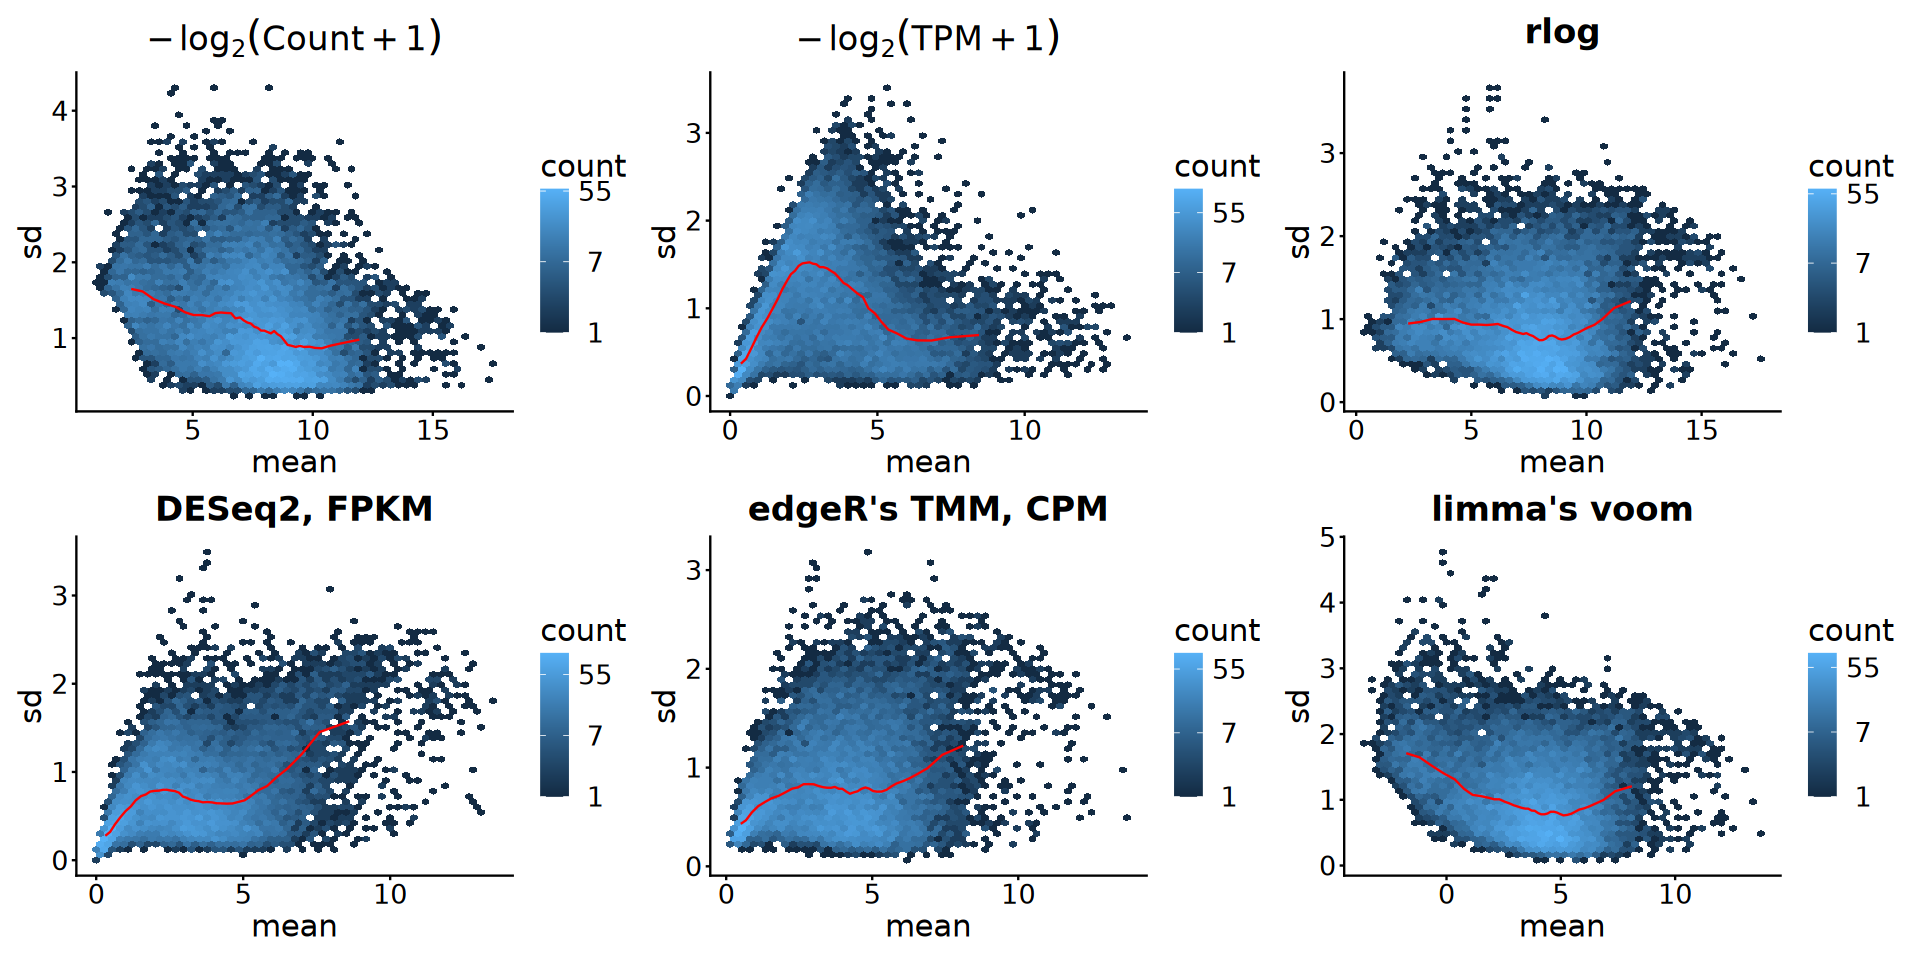

In [22]:
options(repr.plot.width = 16, repr.plot.height = 8)
(p1 + p2 + p3) / (p4 + p5 + p6)

# 4. Exploration

In [23]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [24]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Group, Fraction, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

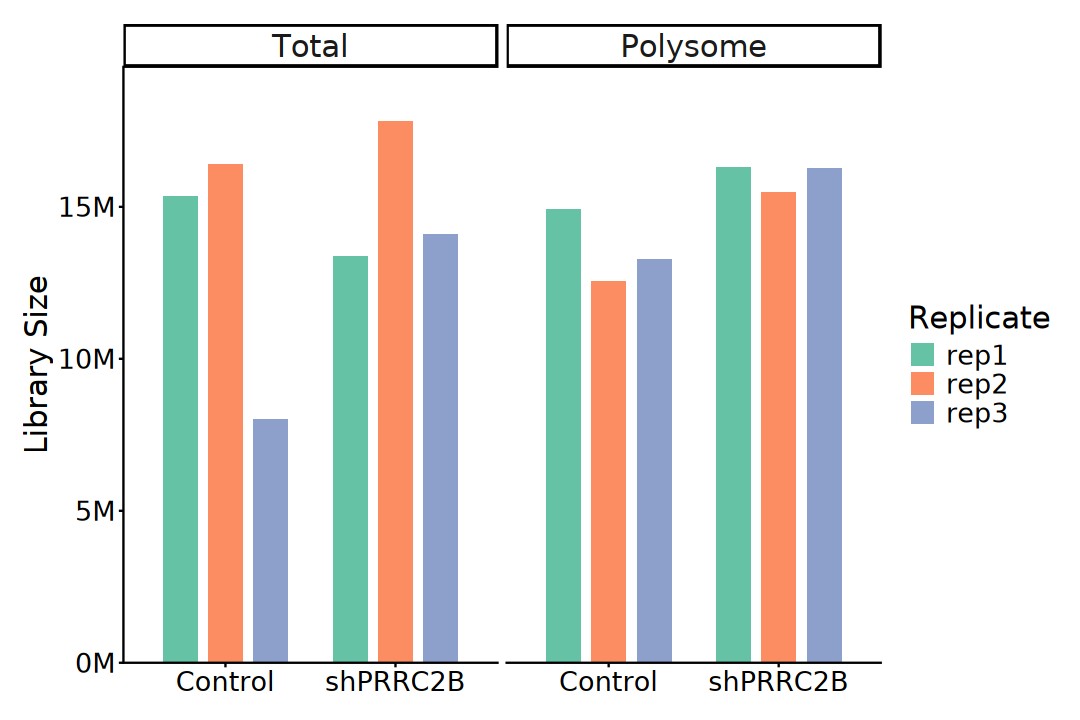

In [25]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = librarySize, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, linewidth = 1.5) +
    facet_wrap(~ Fraction, nrow = 1) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). PCA

In [26]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 1000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [27]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [28]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    facet_wrap( ~ Fraction, nrow = 1, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [29]:
pca_res <- plotPCA(
    rld, intgroup = c("Group", "Fraction", "Replicate"), 
    ntop = 1000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=1000 top features by variance



In [ ]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Fraction), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [31]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [ ]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Group, shape = Fraction), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

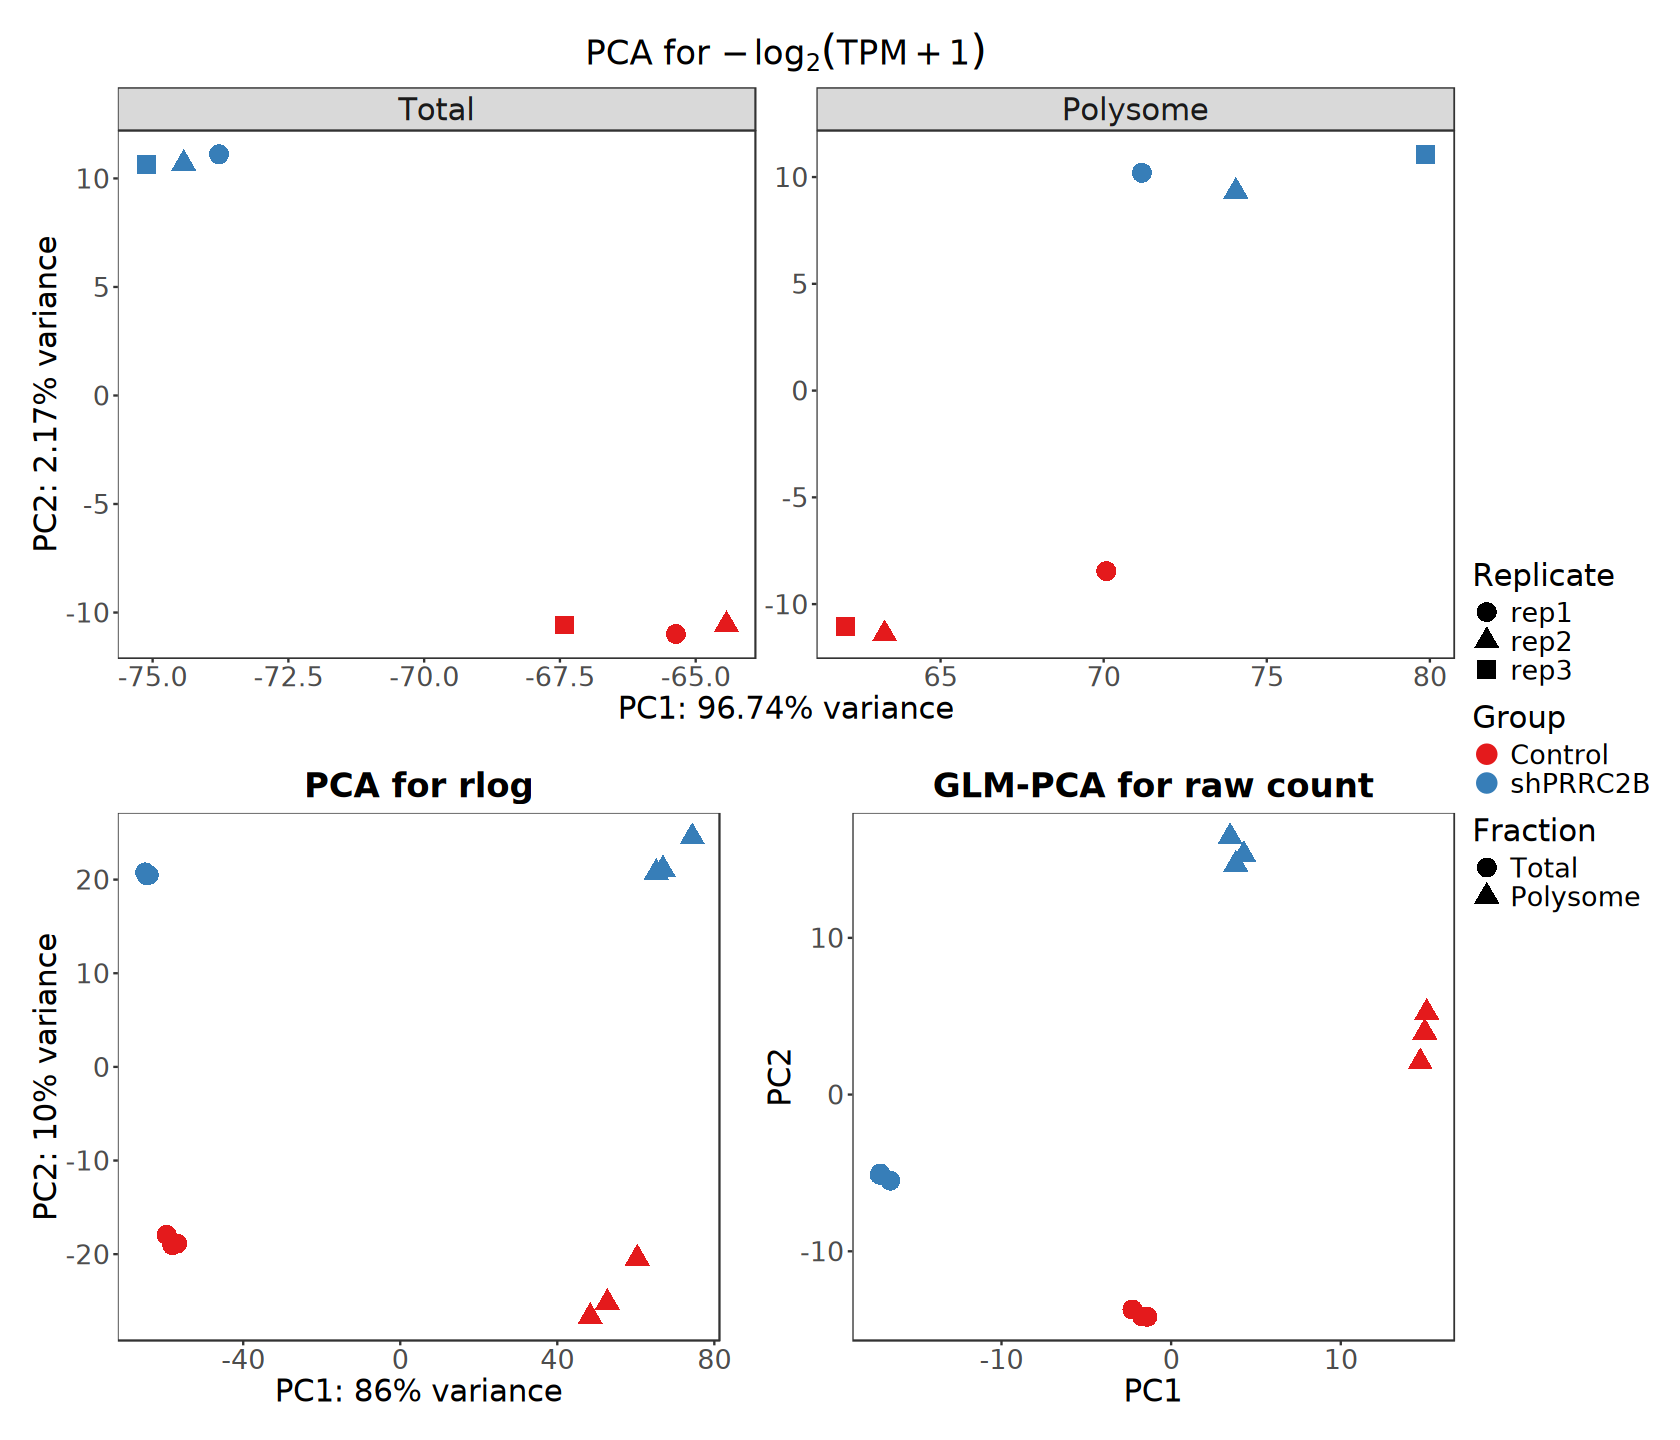

In [33]:
options(repr.plot.width = 14, repr.plot.height = 12)

p1 / (p2 + p3) + plot_layout(nrow = 2, guides = "collect")

## 3). MDS

> Multidimensional scaling

In [34]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

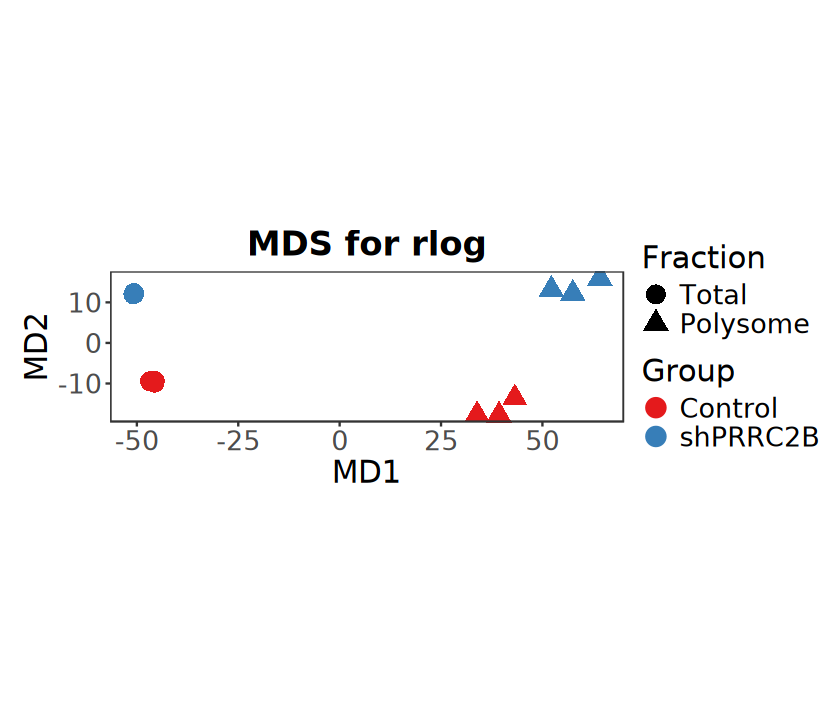

In [35]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Group, shape = Fraction), size = 5) +
    # facet_wrap( ~ Fraction, nrow = 1) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [36]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

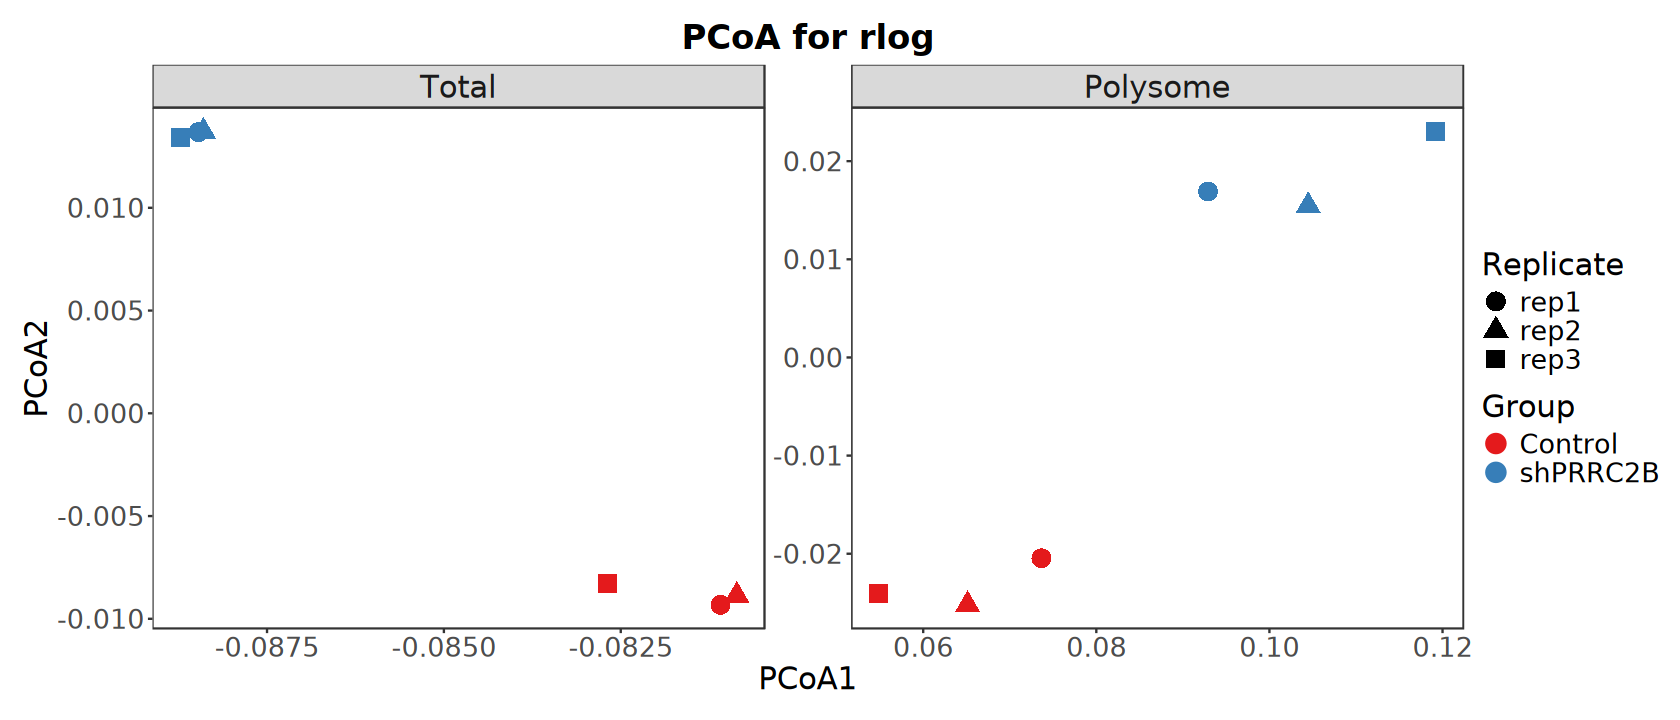

In [37]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    facet_wrap( ~ Fraction, nrow = 1, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    ggtitle("PCoA for rlog") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [38]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Fraction, Group)

In [39]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
fraction_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Fraction)),
    levels(eSet$Fraction))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Group = group_colors,
    Fraction = fraction_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [40]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

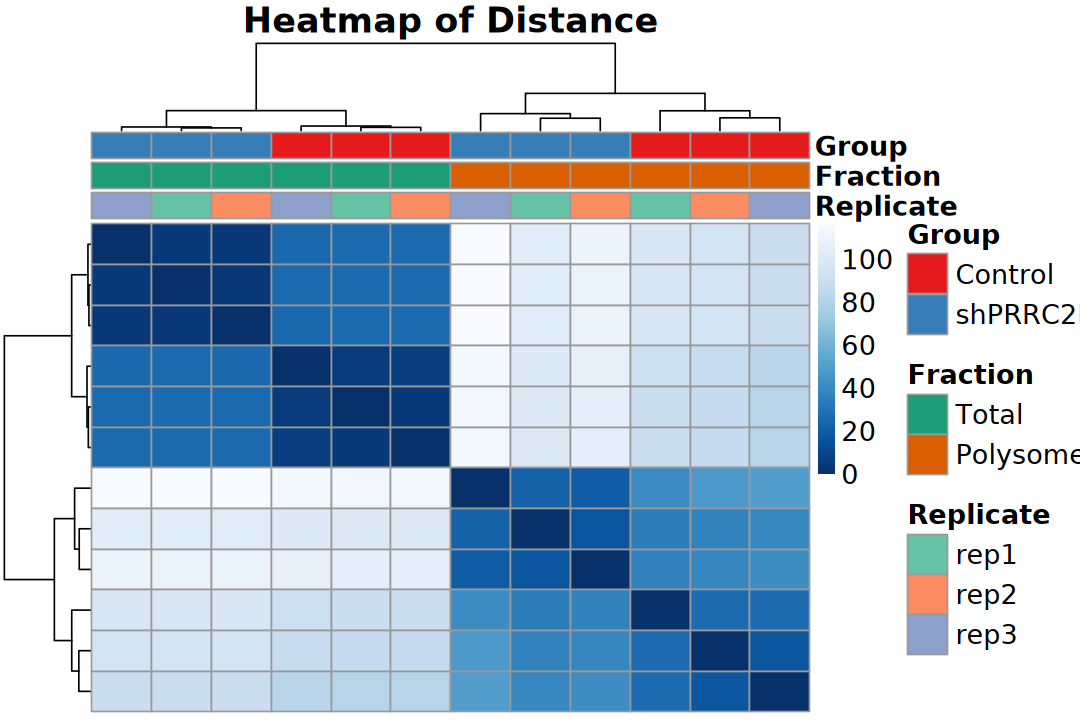

In [41]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [42]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

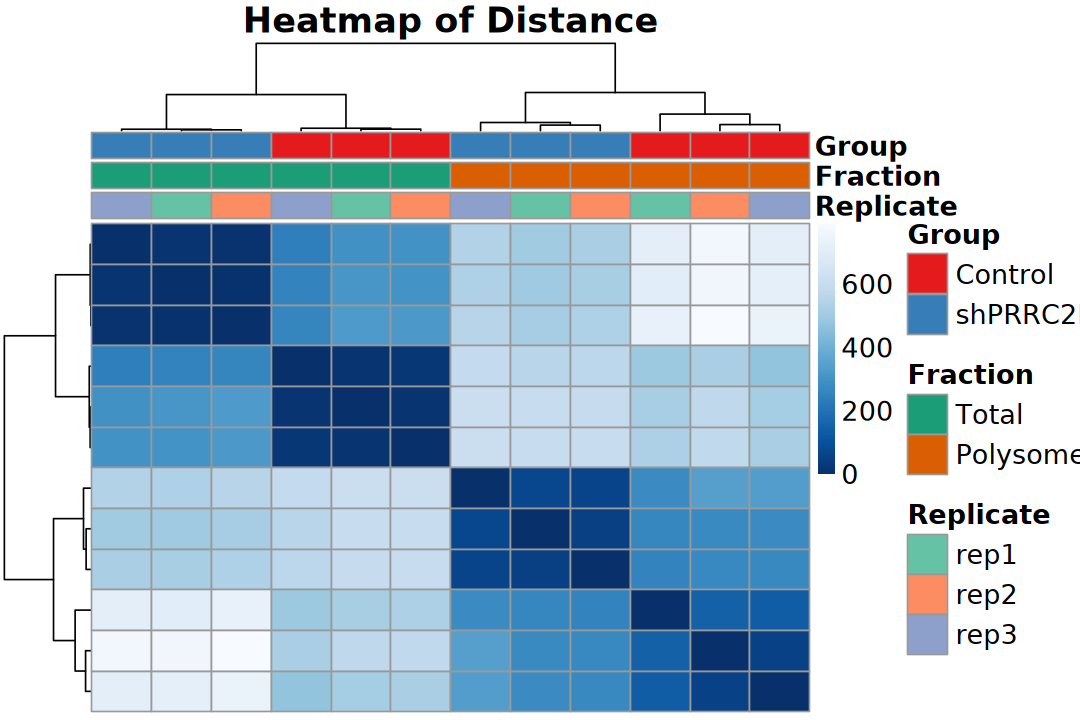

In [43]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [44]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

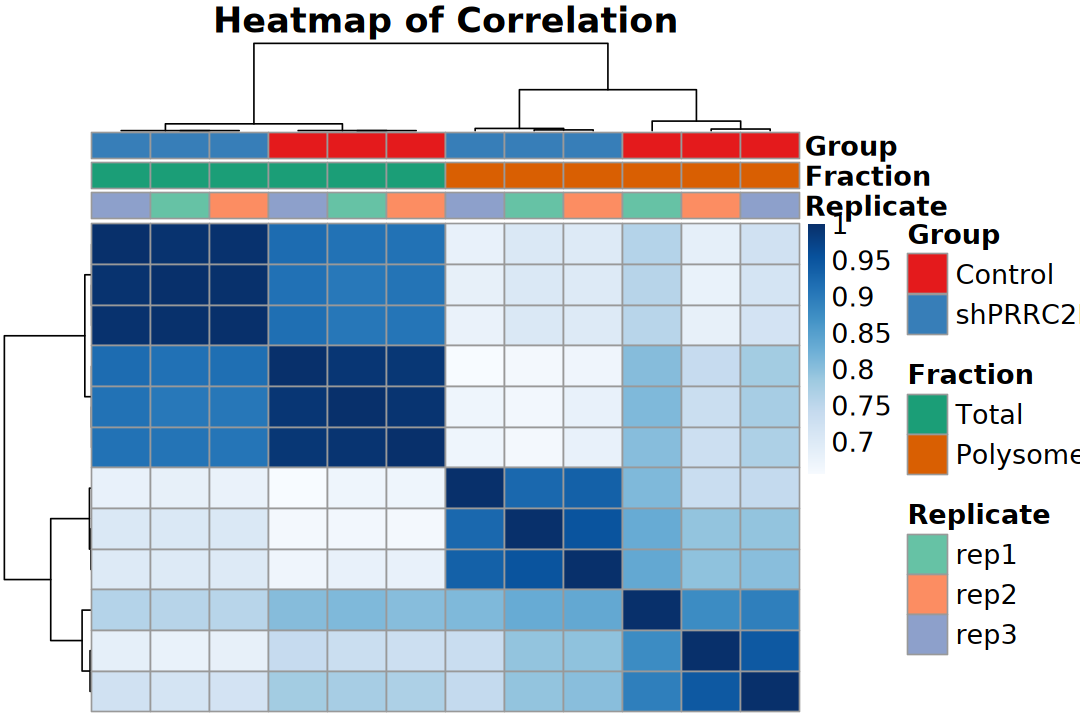

In [45]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

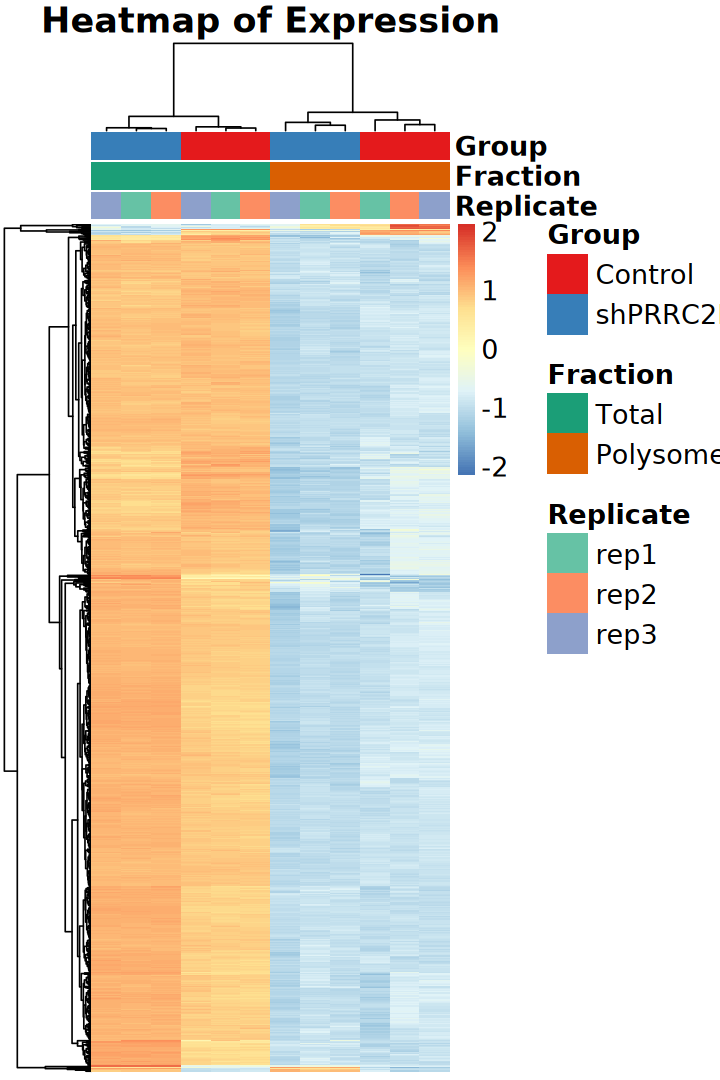

In [46]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. Translation Efficiency

<span style="font-size: 150%">

$$\log_2(\text{TE}) = \log_2\left(\frac{Polysome\ TPM}{Total\ TPM}\right)$$

$$\log_2(\text{TE}) = \log_2(\text{Polysome\ TPM}) - \log_2(\text{Total\ TPM})$$

</span>

In [47]:
calculate_log2_te <- function(
    exprmat, coldata, 
    group_col = "Group", group = c("Control", "Treat"), 
    fraction_col = "Fraction", fraction = c("Total", "Polysome"), 
    replicate_col = "Replicate", replicate = NULL, epsilon = 0) {
    
    # 1. Subset metadata for Total and Polysome fractions
    total_info <- coldata[coldata[[group_col]] == group & 
        coldata[[fraction_col]] == fraction[1], ]
    poly_info  <- coldata[coldata[[group_col]] == group & 
        coldata[[fraction_col]] == fraction[2], ]
    
    # 2. Handle biological replicates matching
    if (!is.null(replicate)) {
        if (is.numeric(replicate) && length(replicate) == 1) {
            sample_rep_vals <- as.character(coldata[[replicate_col]])
            replicate_ids <- if (any(grepl("rep", sample_rep_vals))) {
                paste0("rep", 1:replicate)
            } else {
                as.character(1:replicate)
            }
        } else {
            replicate_ids <- as.character(replicate)
        }
    
        total_info <- total_info[total_info[[replicate_col]] %in% replicate_ids, ]
        poly_info  <- poly_info[poly_info[[replicate_col]] %in% replicate_ids, ]

        # Ensure exact matching order of replicates between Total and Poly fractions
        poly_info  <- poly_info[match(
            total_info[[replicate_col]], poly_info[[replicate_col]]), ]
    
    }

    # 3. Extract expression matrices and compute log2 Translation Efficiency (TE)
    expr_total <- exprmat[, rownames(total_info), drop = FALSE]
    expr_poly  <- exprmat[, rownames(poly_info), drop = FALSE]
    
    log2_te <- log2(expr_poly + epsilon) - log2(expr_total + epsilon)

    # 4. Construct highly scalable column names automatically
    if (!is.null(replicate)) {
        colnames(log2_te) <- paste0(
            "log2TE_", group, "_", total_info[[replicate_col]])
    } else {
        if (nrow(total_info) == 1) {
            colnames(log2_te) <- paste0("log2TE_", group)
        } else {
            colnames(log2_te) <- paste0(
                "log2TE_", group, "_sample", 1:nrow(total_info))
        }
    }

    # 5. Convert all non-finite values (Inf, -Inf, NaN) to NA
    log2_te[!is.finite(log2_te)] <- NA
    
    return(as.matrix(log2_te))
}

In [48]:
te_ctrl  <- calculate_log2_te(
    tpm, colData(eSet), group = "Control", replicate = 3) |>
    rowMeans(na.rm = TRUE)
te_treat <- calculate_log2_te(
    tpm, colData(eSet), group = "shPRRC2B", replicate = 3) |>
    rowMeans(na.rm = TRUE)

te_matrix <- cbind(te_ctrl, te_treat)
te_df <- te_matrix |> as.data.frame() |>
    rownames_to_column("gene_id") |>
    left_join(
        rowData(eSet) |> as.data.frame() |> 
            dplyr::select(-basepairs) |> 
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")
head(te_df)

,te_ctrl,te_treat,symbol,type
,<dbl>,<dbl>,<chr>,<chr>
ENSG00000187634.13,-2.2913000,-1.708977,SAMD11,protein_coding
ENSG00000188976.11,-4.0045808,-4.982005,NOC2L,protein_coding
ENSG00000187961.15,-4.1335131,-3.642909,KLHL17,protein_coding
ENSG00000187583.11,-3.8040053,-2.516950,PLEKHN1,protein_coding
ENSG00000187642.10,1.9667377,-2.127919,PERM1,protein_coding
ENSG00000188290.11,0.1017054,1.524761,HES4,protein_coding


In [49]:
# 1. Create logical matrices to identify infinite and missing/NaN values
has_inf <- is.infinite(te_df$te_ctrl) | is.infinite(te_df$te_treat)
has_nan_or_na <- is.na(te_df$te_ctrl) | is.na(te_df$te_treat)

# 2. Combine conditions: a row is marked TRUE if it contains any abnormal value
rows_with_abnormal <- has_inf | has_nan_or_na

# 3. Extract rows containing abnormal values
abnormal_data <- te_df[rows_with_abnormal, , drop = FALSE]

# 4. Output results to the console
if (nrow(abnormal_data) > 0) {
    cat("Warning: Found", nrow(abnormal_data), "row(s) with abnormal values:\n")
    print(head(abnormal_data, 10))
} else {
    cat("Success: No Inf, -Inf, NaN, or NA values detected in the table.\n")
}

# Keep only rows that do not contain any abnormal values
# te_df <- te_df[!rows_with_abnormal, , drop = FALSE]

                   te_ctrl  te_treat  symbol           type
ENSG00000169962.5      NaN -3.538306  TAS1R3 protein_coding
ENSG00000205116.4      NaN       NaN TMEM88B protein_coding
ENSG00000142609.20     NaN -1.305023  CFAP74 protein_coding
ENSG00000149527.18     NaN       NaN   PLCH2 protein_coding
ENSG00000197241.4      NaN  2.435920  SLC2A7 protein_coding
ENSG00000204624.8      NaN -3.843409   DISP3 protein_coding
ENSG00000162490.7      NaN -4.490409  DRAXIN protein_coding
ENSG00000175206.11     NaN       NaN    NPPA protein_coding
ENSG00000117148.8      NaN -3.951178   ACTL8 protein_coding
ENSG00000211454.16     NaN -4.496401   AKR7L protein_coding


# 6. DTEGs

In [50]:
logfc_cutoff <- log2(2)
p_cutoff <- 0.05

## 1). DESeq2

> median of ratios for normalization

<span style="font-size: 150%">

$$\log_2\text{FC} = \log_2\left( \frac{\text{Polysome}_{\text{treat}}}{\text{Total}_{\text{treat}}} \right) - \log_2\left( \frac{\text{Polysome}_{\text{ctrl}}}{\text{Total}_{\text{ctrl}}} \right)$$

</span>

In [51]:
design(dds)

~Group * Fraction

In [52]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [53]:
resultsNames(dds)

[1] "Intercept"                      "Group_shPRRC2B_vs_Control"     
[3] "Fraction_Polysome_vs_Total"     "GroupshPRRC2B.FractionPolysome"

### a). Standard

In [54]:
# Examining whether treatment responses differ between the two cell types
res <- results(
    dds, name = "GroupshPRRC2B.FractionPolysome",
    lfcThreshold = logfc_cutoff, alpha = p_cutoff)

summary(res)


out of 13970 with nonzero total read count
adjusted p-value < 0.05
LFC > 1.00 (up)    : 18, 0.13%
LFC < -1.00 (down) : 51, 0.37%
outliers [1]       : 0, 0%
low counts [2]     : 271, 1.9%
(mean count < 6)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [55]:
deseq2_result <- res |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_result$result)
head(deseq2_result)


   Up  Down    NS 
   18    51 13901 

,baseMean,logFC,lfcSE,stat,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSG00000187634.13,1291.430281,0.7188753,0.1594256,4.509159,0.96108011,1.0000000,NS,SAMD11,protein_coding,2682
ENSG00000188976.11,1539.414873,-0.8707765,0.2641122,-3.296995,0.68767652,1.0000000,NS,NOC2L,protein_coding,2247
ENSG00000187961.15,337.696449,0.6023222,0.2934359,2.052654,0.91233043,1.0000000,NS,KLHL17,protein_coding,2003
ENSG00000187583.11,14.708779,2.1521434,0.9175930,2.345423,0.10492384,1.0000000,NS,PLEKHN1,protein_coding,1989
ENSG00000187642.10,7.005589,-3.3095543,1.9680775,-1.681618,0.13456810,1.0000000,NS,PERM1,protein_coding,2400
ENSG00000188290.11,10016.621739,1.5913112,0.2679258,5.939373,0.01365716,0.6320589,NS,HES4,protein_coding,741


### b). LFC Shrink

> Shrinkage of effect size (LFC estimates) is useful for visualization and ranking of genes.

In [56]:
# Examining whether treatment responses differ between the two cell types
res_lfc <- lfcShrink(dds, coef = "GroupshPRRC2B.FractionPolysome", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 13970 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 2152, 15%
LFC < 0 (down)     : 2536, 18%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 2)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [57]:
deseq2_lfc_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_lfc_result$result)
head(deseq2_lfc_result)


   Up  Down    NS 
  479   812 12679 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSG00000187634.13,1291.430281,0.6794774,0.1598131,6.508522e-06,1.105408e-04,NS,SAMD11,protein_coding,2682
ENSG00000188976.11,1539.414873,-0.7630156,0.2679978,9.772516e-04,6.672632e-03,NS,NOC2L,protein_coding,2247
ENSG00000187961.15,337.696449,0.4696900,0.2825705,4.010616e-02,1.142269e-01,NS,KLHL17,protein_coding,2003
ENSG00000187583.11,14.708779,1.0567008,1.1693470,1.900552e-02,6.512315e-02,NS,PLEKHN1,protein_coding,1989
ENSG00000187642.10,7.005589,-0.1606565,0.4746163,9.264296e-02,2.082181e-01,NS,PERM1,protein_coding,2400
ENSG00000188290.11,10016.621739,1.5053722,0.2728294,2.861140e-09,1.364168e-07,Up,HES4,protein_coding,741


In [58]:
comparison_df <- deseq2_result |> 
    rownames_to_column("gene_id") |>
    dplyr::select(gene_id, result_raw = result) |> 
    inner_join(
        deseq2_lfc_result |> 
            rownames_to_column("gene_id") |>
            dplyr::select(gene_id, result_lfc = result),
        by = c("gene_id"))

cat("\n=========================================\n")
print(table(
    Raw = comparison_df$result_raw, 
    LFC_Shrink = comparison_df$result_lfc))


      LFC_Shrink
Raw       Up  Down    NS
  Up      18     0     0
  Down     0    51     0
  NS     461   761 12679


## 2). edgeR

> Trimmed Mean of M-values (TMM)

### a). Negative binomial GLM framework

In [59]:
design <- model.matrix(~ Group * Fraction, data = dgel$samples)
colnames(design)

[1] "(Intercept)"                    "GroupshPRRC2B"                 
[3] "FractionPolysome"               "GroupshPRRC2B:FractionPolysome"

In [60]:
dgel_nbglm <- estimateDisp(dgel, design)
# # Estimate common dispersion
# dgel <- estimateGLMCommonDisp(dge, design)
# # Estimate trended dispersions
# dgel <- estimateGLMTrendedDisp(dgel, design)
# # Estimate tagwise dispersions
# dgel <- estimateGLMTagwiseDisp(dgel, design)

In [61]:
# likelihood ratio test
fit <- glmFit(dgel_nbglm, design)
lrt <- glmLRT(fit, coef = "GroupshPRRC2B:FractionPolysome")

In [62]:
edger_glm_lrt_result <- topTags(lrt, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_lrt_result$result)
head(edger_glm_lrt_result)


   Up  Down    NS 
  763  1177 12055 

,symbol,type,basepairs,logFC,logCPM,LR,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSG00000148773.14,MKI67,protein_coding,9768,-3.228274,7.612693,186.37703,1.964202e-42,2.748901e-38,Down
ENSG00000111642.16,CHD4,protein_coding,6249,-2.149029,6.118219,116.80380,3.169176e-27,2.217631e-23,Down
ENSG00000153201.17,RANBP2,protein_coding,9831,-2.482349,6.881124,112.24213,3.162331e-26,1.475228e-22,Down
ENSG00000086758.17,HUWE1,protein_coding,13371,-2.296558,8.535957,100.18212,1.390091e-23,4.863579e-20,Down
ENSG00000126883.19,NUP214,protein_coding,6712,-2.304792,5.311818,92.50992,6.698827e-22,1.875002e-18,Down
ENSG00000124486.15,USP9X,protein_coding,7725,-1.881149,8.043981,89.11982,3.716098e-21,8.667799e-18,Down


### b). Quasi-likelihood pipeline (edgeR v3)

In [63]:
design <- model.matrix(~ Group * Fraction, data = dgel$samples)

In [64]:
dgel_nbglm <- estimateDisp(dgel, design)

In [65]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel_nbglm, design)
qlf <- glmQLFTest(fit, coef = "GroupshPRRC2B:FractionPolysome")

In [66]:
edger_glm_qlf_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_result$result)
head(edger_glm_qlf_result)


   Up  Down    NS 
  576   988 12431 

,symbol,type,basepairs,logFC,logCPM,F,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSG00000148773.14,MKI67,protein_coding,9768,-3.226906,7.612693,196.96716,2.026528e-11,2.836126e-07,Down
ENSG00000111642.16,CHD4,protein_coding,6249,-2.148863,6.118219,130.87945,6.445739e-10,4.510406e-06,Down
ENSG00000153201.17,RANBP2,protein_coding,9831,-2.480691,6.881124,120.71121,1.255725e-09,5.857959e-06,Down
ENSG00000086758.17,HUWE1,protein_coding,13371,-2.294938,8.535957,107.87717,3.135408e-09,1.097001e-05,Down
ENSG00000126883.19,NUP214,protein_coding,6712,-2.304606,5.311818,99.36163,6.093229e-09,1.450142e-05,Down
ENSG00000124486.15,USP9X,protein_coding,7725,-1.880472,8.043981,99.06090,6.217116e-09,1.450142e-05,Down


In [67]:
comparison_df <- edger_glm_lrt_result |> 
    rownames_to_column("gene_id") |>
    dplyr::select(gene_id, glm_lrt = result) |> 
    inner_join(
        edger_glm_qlf_result |> 
            rownames_to_column("gene_id") |>
            dplyr::select(gene_id, glm_qlf = result),
        by = c("gene_id"))

cat("\n=========================================\n")
print(table(
    glm_lrt = comparison_df$glm_lrt, 
    glm_qlf = comparison_df$glm_qlf))


       glm_qlf
glm_lrt    Up  Down    NS
   Up     572     0   191
   Down     0   987   190
   NS       4     1 12050


## 3). limma-voom

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

In [68]:
design <- model.matrix(~ Group * Fraction, data = dgel$samples)

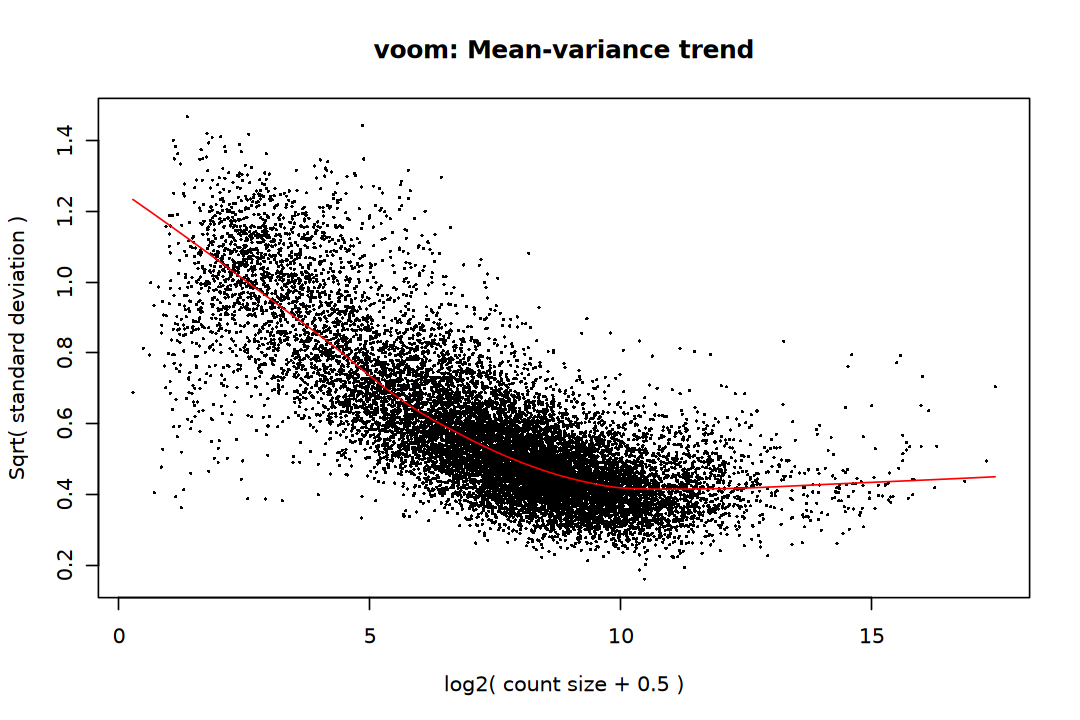

In [69]:
options(repr.plot.width = 9, repr.plot.height = 6)
norm_v <- voom(dgel, design, plot = TRUE)

In [70]:
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit)

In [71]:
limma_voom_result <- topTable(efit, coef = "GroupshPRRC2B:FractionPolysome", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voom_result$result)
head(limma_voom_result)


   Up  Down    NS 
  602   881 12512 

,symbol,type,basepairs,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSG00000148773.14,MKI67,protein_coding,9768,-3.227402,6.051575,-12.75451,3.230766e-10,4.521457e-06,12.77325,Down
ENSG00000111642.16,CHD4,protein_coding,6249,-2.137978,5.559522,-11.17433,2.506945e-09,1.706979e-05,11.43040,Down
ENSG00000124486.15,USP9X,protein_coding,7725,-1.889403,7.105964,-10.89181,3.702683e-09,1.706979e-05,11.22828,Down
ENSG00000153201.17,RANBP2,protein_coding,9831,-2.491819,5.881096,-10.67600,5.013739e-09,1.706979e-05,10.74610,Down
ENSG00000086758.17,HUWE1,protein_coding,13371,-2.293777,7.091037,-10.53828,6.098533e-09,1.706979e-05,10.66656,Down
ENSG00000130066.17,SAT1,protein_coding,524,1.724549,5.570197,10.26045,9.106949e-09,2.124196e-05,10.40801,Up


In [72]:
comparison_df <- limma_voom_result |> 
    rownames_to_column("gene_id") |>
    dplyr::select(gene_id, limma = result) |> 
    inner_join(
        edger_glm_qlf_result |> 
            rownames_to_column("gene_id") |>
            dplyr::select(gene_id, edger = result),
        by = c("gene_id"))

cat("\n=========================================\n")
print(table(
    limma = comparison_df$limma, 
    edger = comparison_df$edger))

      edger
limma     Up  Down    NS
  Up     528     0    74
  Down     0   846    35
  NS      48   142 12322


## DEGs Evaluation

In [73]:
add_label <- function(res, symbol_col = "symbol", type_col = "type") {
    res |> rownames_to_column("gene_id") |>
        dplyr::group_by(result) |>
        dplyr::arrange(padj, dplyr::desc(abs(logFC)), .by_group = TRUE) |>
        dplyr::mutate(
            valid = .data[[type_col]] == "protein_coding" & 
                result %in% c("Up", "Down"),
            label = dplyr::if_else(
                valid & cumsum(valid) <= 5, 
                .data[[symbol_col]], NA_character_)
        ) |>
        dplyr::ungroup() |>
        column_to_rownames("gene_id")
}

In [74]:
deseq2_result <- add_label(deseq2_lfc_result, symbol_col = "symbol")
edger_result <- add_label(edger_glm_qlf_result, symbol_col = "symbol")
limma_result <- add_label(limma_voom_result, symbol_col = "symbol")

### MA Plot

> - Mean-Difference plot
> - Bland-Altman plot

In [75]:
ggplot_maplot <- function(plot_df, col, log = FALSE, title = NULL) {
    if(log) {
        x_vals <- log2(plot_df[[col]] + 1)
    } else {
        x_vals <- plot_df[[col]]
    }

    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()

    ggplot(plot_df, aes(x = x_vals, y = logFC)) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        labs(
            title = paste0("MA plot (", title,")"), , color = "DEG",
            x = "Mean Expression", y = "log2FC") +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))
}

In [76]:
p1 <- ggplot_maplot(deseq2_result, col = "baseMean", log = TRUE, title = "DESeq2")
p2 <- ggplot_maplot(edger_result, col = "logCPM", title = "edgeR")
p3 <- ggplot_maplot(limma_result, col = "AveExpr", title = "limma-voom")

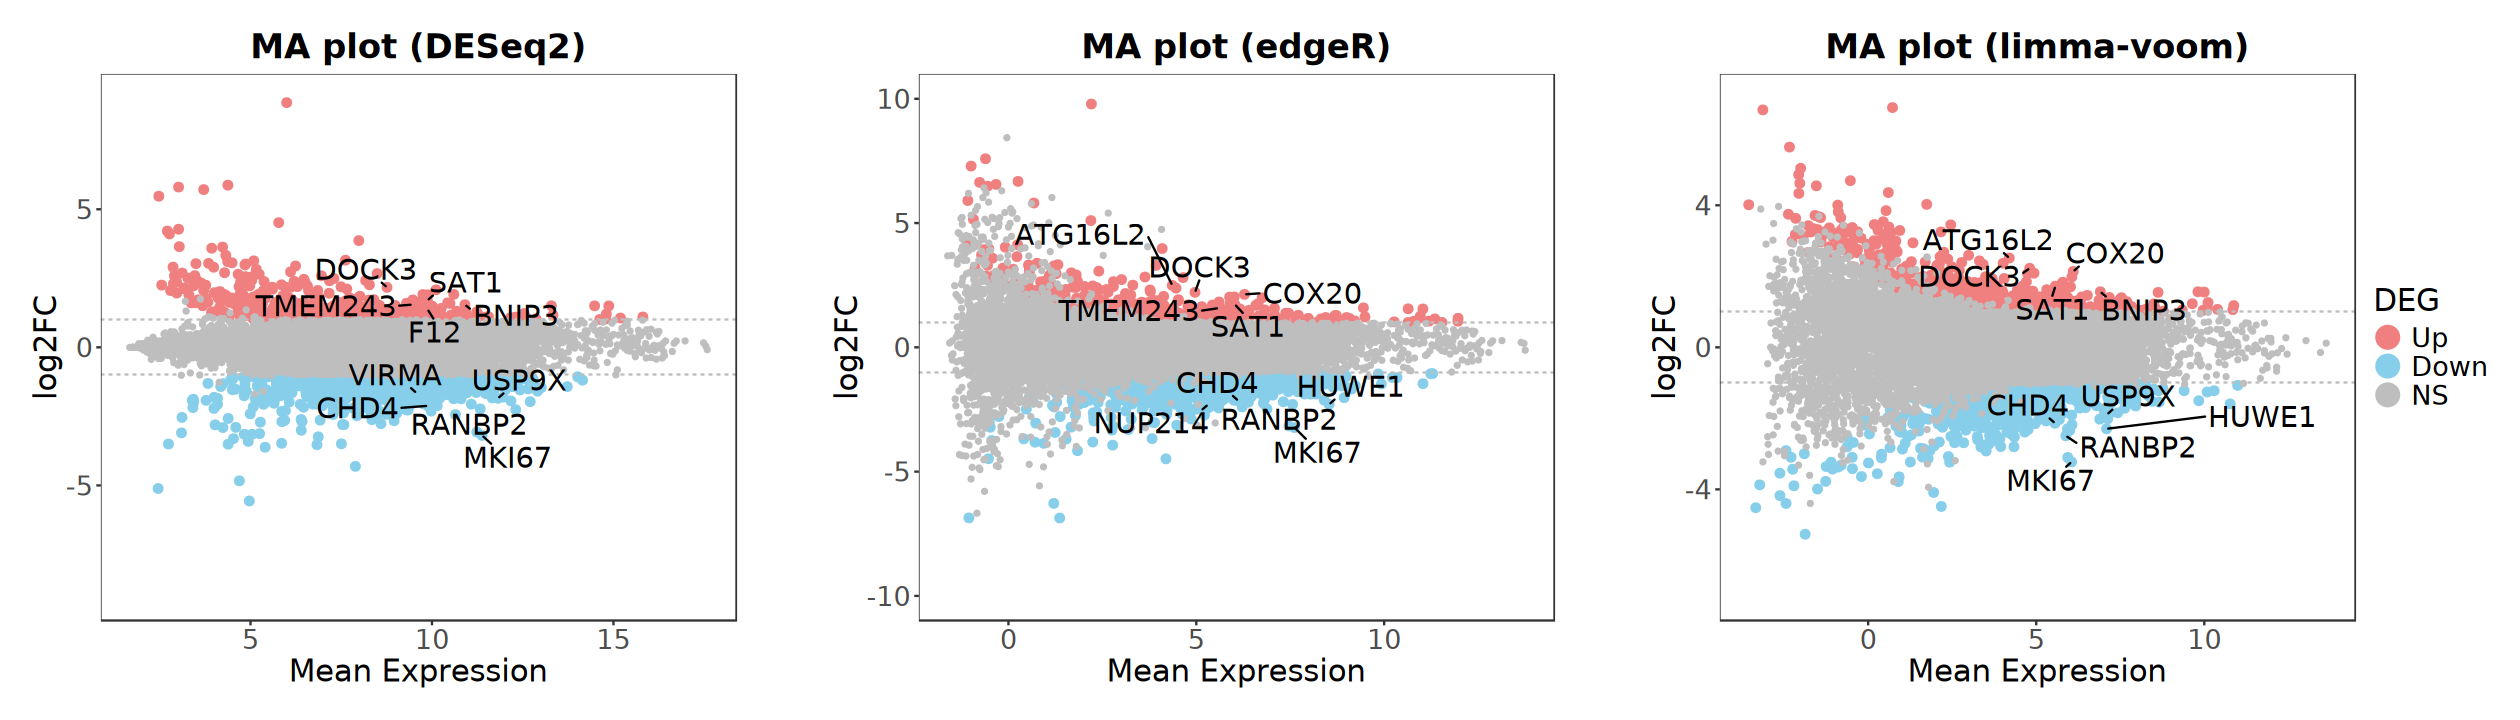

In [77]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Volcano

In [78]:
ggplot_volcano <- function(plot_df, title = NULL) {
    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()
    min_padj <- plot_df$padj |> pmax(1e-300) |> 
        (\(x) -log10(x))() |> max(na.rm = TRUE) |> 
        (\(x) ceiling(x / 5) * 5)()

    ggplot(plot_df, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        ggrepel::geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 4, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        labs(
            title = paste0("Volcano (", title,")"), , color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))
}

In [79]:
p1 <- ggplot_volcano(deseq2_result, title = "DESeq2")
p2 <- ggplot_volcano(edger_result, title = "edgeR")
p3 <- ggplot_volcano(limma_result, title = "limma-voom")

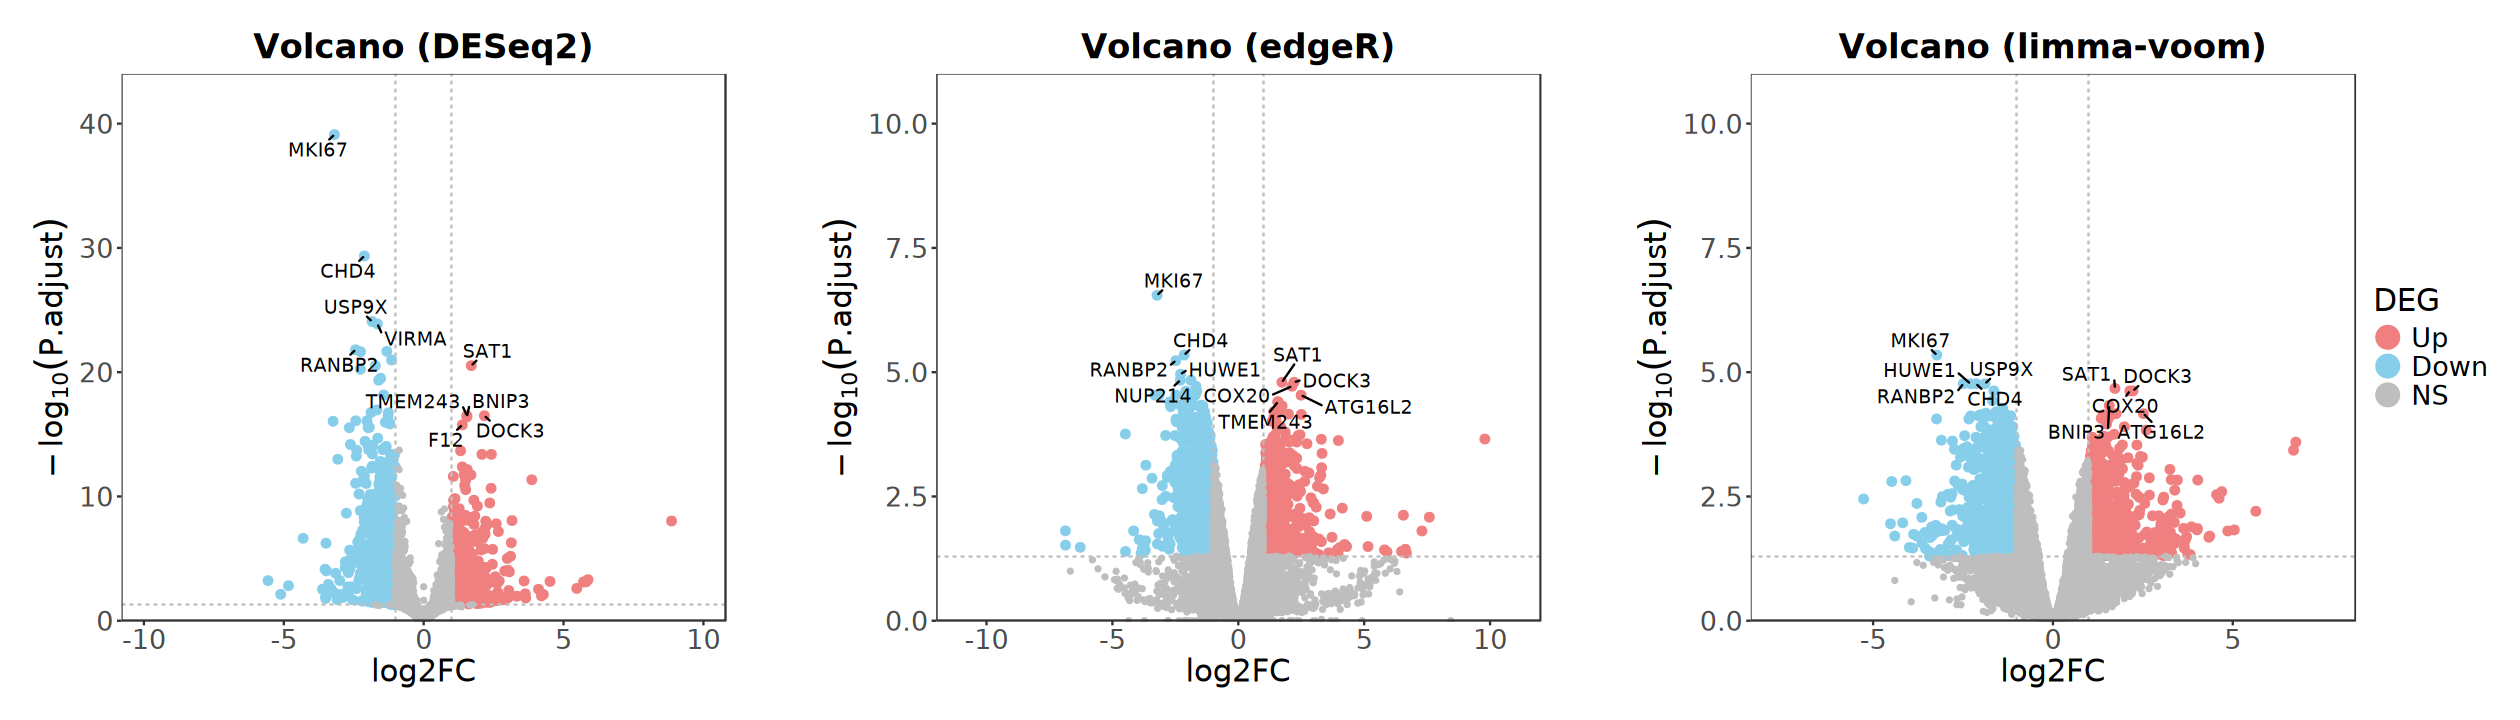

In [80]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Venn

In [81]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [82]:
genes_up <- list(
    DESeq2 = deseq2_result[deseq2_result$result == "Up", "symbol"], 
    edgeR = edger_result[edger_result$result == "Up", "symbol"], 
    limma = limma_result[limma_result$result == "Up", "symbol"])
genes_up <- lapply(genes_up, unique)

In [83]:
genes_down <- list(
    DESeq2 = deseq2_result[deseq2_result$result == "Down", "symbol"], 
    edgeR = edger_result[edger_result$result == "Down", "symbol"], 
    limma = limma_result[limma_result$result == "Down", "symbol"])
genes_down <- lapply(genes_down, unique)

In [84]:
p1 <- ggVennDiagram(genes_up, set_color = "grey", set_size = 6, 
                    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(genes_down, set_color = "grey", set_size = 6, 
                    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

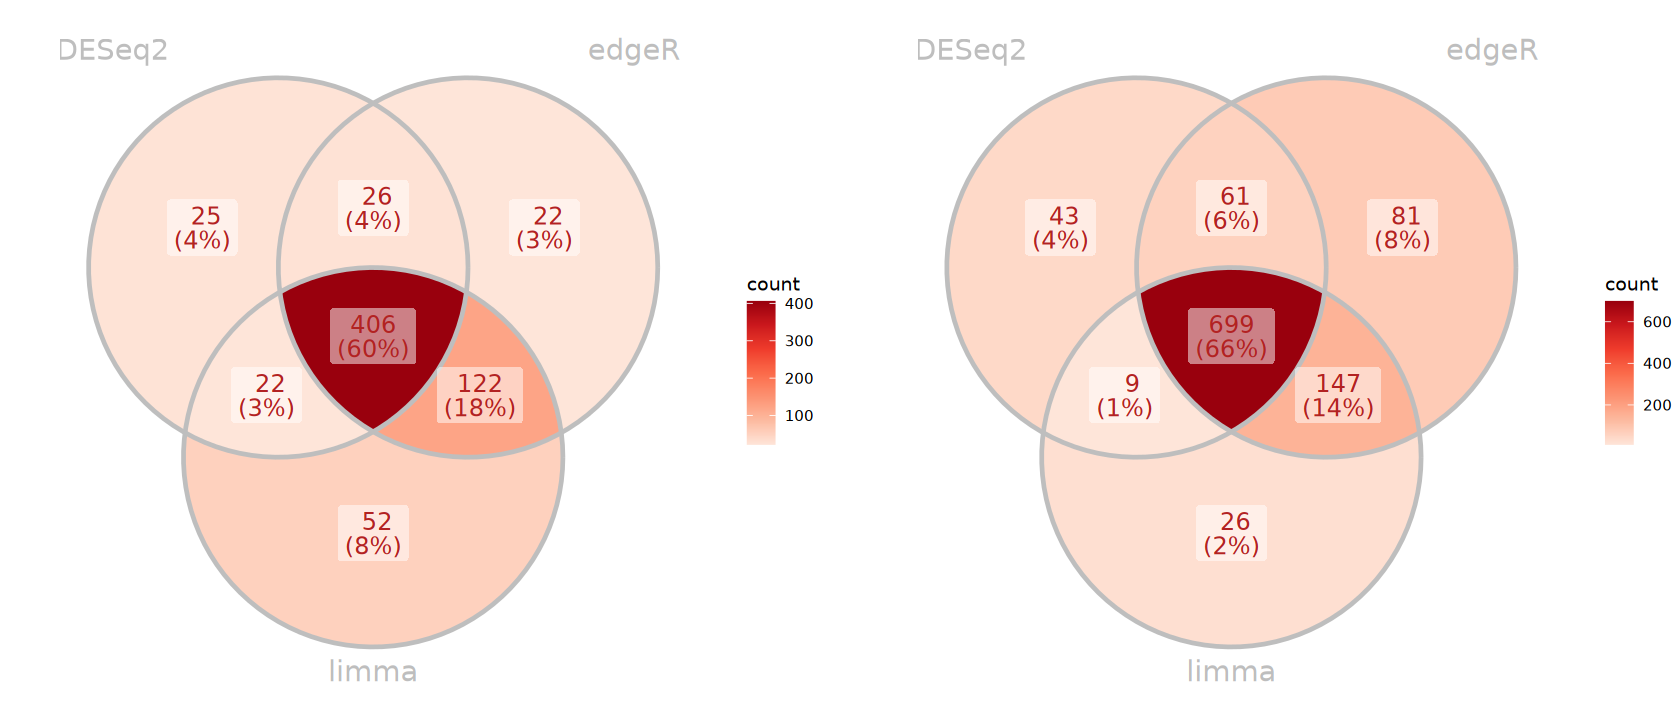

In [85]:
options(repr.plot.width = 14, repr.plot.height = 6)
p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## DEGs Visualization

In [86]:
degs_result <- left_join(
    deseq2_result |> rownames_to_column("gene_id"), 
    te_matrix |> as.data.frame() |> rownames_to_column("gene_id"), 
    by = "gene_id") |>
    column_to_rownames("gene_id")

head(degs_result)

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs,valid,label,te_ctrl,te_treat
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<lgl>,<chr>,<dbl>,<dbl>
ENSG00000130066.17,936.8864,1.700452,0.1711383,1.957668e-24,2.957436e-21,Up,SAT1,protein_coding,524,TRUE,SAT1,-0.79054847,0.8012276
ENSG00000088538.13,433.0000,2.170968,0.2443699,4.321189e-20,3.177211e-17,Up,DOCK3,protein_coding,6090,TRUE,DOCK3,-3.58798350,-1.4756037
ENSG00000135185.12,702.3326,1.546612,0.1734481,4.226246e-20,3.177211e-17,Up,TMEM243,protein_coding,477,TRUE,TMEM243,-0.06165957,1.3898664
ENSG00000176171.12,1920.6852,1.543675,0.1733813,5.910935e-20,3.932179e-17,Up,BNIP3,protein_coding,611,TRUE,BNIP3,-1.80393044,-0.3618551
ENSG00000131187.11,939.7760,1.380686,0.1587627,3.464566e-19,1.728571e-16,Up,F12,protein_coding,2190,TRUE,F12,-0.48454418,0.7937301
ENSG00000148399.13,626.7521,1.318981,0.1626058,6.602726e-17,2.096365e-14,Up,DPH7,protein_coding,1356,TRUE,NA,-1.81578893,-0.6091417


In [87]:
# 1. Create logical matrices to identify infinite and missing/NaN values
has_inf <- is.infinite(degs_result$te_ctrl) | is.infinite(degs_result$te_treat)
has_nan_or_na <- is.na(degs_result$te_ctrl) | is.na(degs_result$te_treat)

# 2. Combine conditions: a row is marked TRUE if it contains any abnormal value
rows_with_abnormal <- has_inf | has_nan_or_na

# 3. Extract rows containing abnormal values
abnormal_data <- degs_result[rows_with_abnormal, , drop = FALSE]

print(table(abnormal_data$result))

# 4. Output results to the console
if (nrow(abnormal_data[abnormal_data$result %in% c("Up", "Down"), ]) > 0) {
    cat("Warning: Found", nrow(abnormal_data), "row(s) with abnormal values:\n")
    print(abnormal_data[
        abnormal_data$result %in% c("Up", "Down"), 
        c("logFC", "pvalue", "padj", "result", "symbol", "te_ctrl", "te_treat")])
} else {
    cat("Success: No Inf, -Inf, NaN, or NA values detected in the table.\n")
}


  Up Down   NS 
  13    5  268 
                       logFC       pvalue         padj result          symbol
ENSG00000185507.21  8.860865 1.355266e-10 9.390071e-09     Up            IRF7
ENSG00000234511.11  5.872837 4.046157e-05 4.906668e-04     Up         C5orf58
ENSG00000108551.5   5.803011 6.678239e-05 7.457633e-04     Up           RASD1
ENSG00000102145.16  5.472344 2.879005e-04 2.501225e-03     Up           GATA1
ENSG00000116329.12  3.631273 9.960792e-04 6.778074e-03     Up           OPRD1
ENSG00000124772.12  4.277796 1.174302e-03 7.658972e-03     Up           CPNE5
ENSG00000243056.2   4.210700 1.636942e-03 1.000791e-02     Up        EIF4EBP3
ENSG00000158473.8   3.331980 1.768987e-03 1.061544e-02     Up            CD1D
ENSG00000169871.13  2.945963 2.157800e-03 1.240513e-02     Up          TRIM56
ENSG00000142609.20  3.646550 2.634696e-03 1.450225e-02     Up          CFAP74
ENSG00000269466.4   2.823570 4.183747e-03 2.064436e-02     Up            H3Y1
ENSG00000213402.3   2.597019 4.

### Scatter Plot

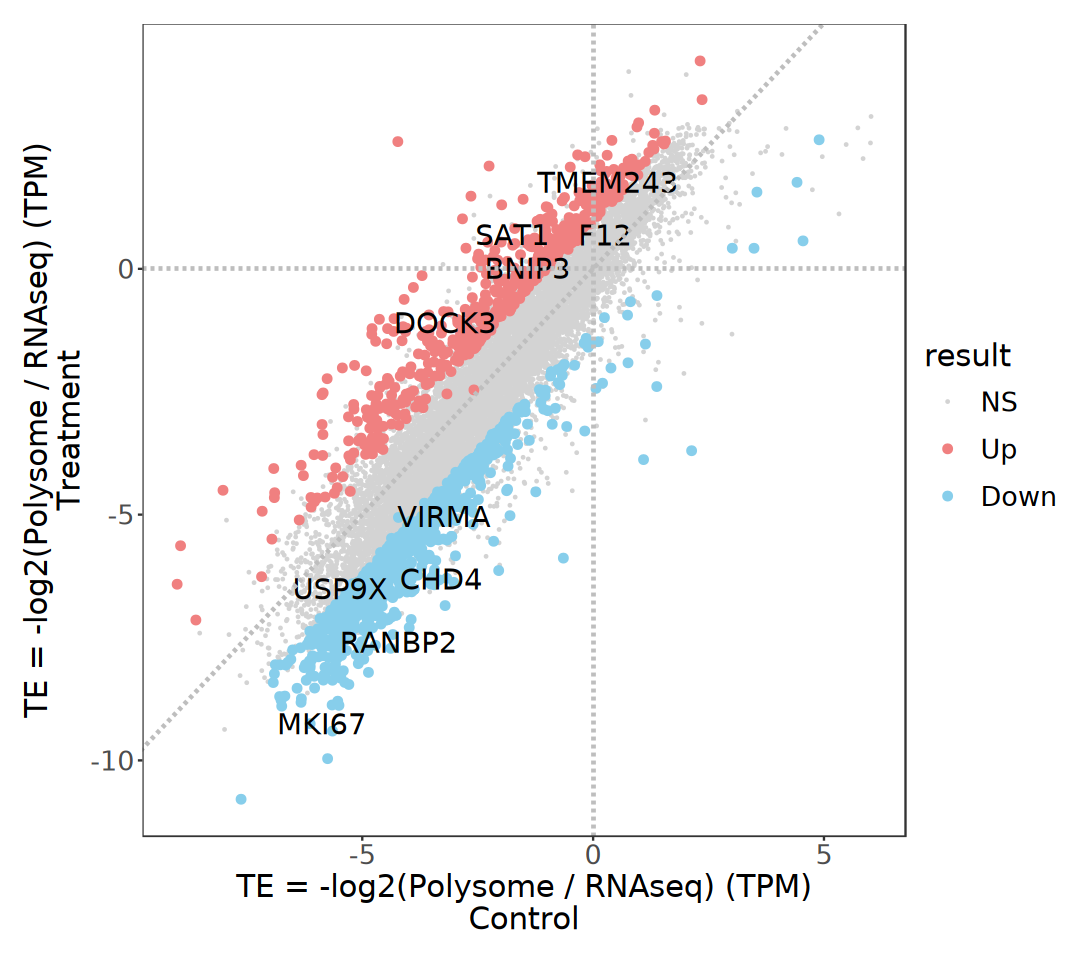

In [88]:
options(repr.plot.width = 9, repr.plot.height = 8)

# axisRange <- c(degs_result$te_ctrl, degs_result$te_treat) |> 
#     na.omit() %>% .[is.finite(.)] |> abs() |> max(na.rm = T) |> ceiling()

ggplot(degs_result, aes(x = te_ctrl, y = te_treat)) +
    geom_point(
        data = subset(degs_result, result == "NS"), 
        aes(color = result, size = result), na.rm = TRUE) + 
    geom_point(
        data = subset(degs_result, result != "NS"), 
        aes(color = result, size = result), na.rm = TRUE) + 
    geom_text_repel(
        aes(label = label),  na.rm = TRUE, size = 6, 
        color = "black", max.overlaps = Inf) +
    geom_hline(
        yintercept = 0, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    geom_vline(
        xintercept = 0, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    geom_abline(
        intercept = 0, slope = 1, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    # xlim(-axisRange, axisRange) + 
    # ylim(-axisRange, axisRange) + 
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "LightGray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 0.3))+
    labs(x = "TE = -log2(Polysome / RNAseq) (TPM)\n Control ", 
         y = "TE = -log2(Polysome / RNAseq) (TPM)\n Treatment ") + 
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [89]:
design(dds)
resultsNames(dds)

~Group * Fraction

[1] "Intercept"                      "Group_shPRRC2B_vs_Control"     
[3] "Fraction_Polysome_vs_Total"     "GroupshPRRC2B.FractionPolysome"

In [90]:
# 1. Extract results from DESeq2
res_total <- results(dds, name = "Group_shPRRC2B_vs_Control")
res_polysome <- results(dds, contrast = list(
    c("Group_shPRRC2B_vs_Control", "GroupshPRRC2B.FractionPolysome")))

In [91]:
# 2. Match and map log2FoldChange columns directly using row names
degs_result$log2FC_total  <- res_total[rownames(degs_result), "log2FoldChange"]
degs_result$log2FC_polysome <- res_polysome[rownames(degs_result), "log2FoldChange"]

head(degs_result)

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs,valid,label,te_ctrl,te_treat,log2FC_total,log2FC_polysome
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<lgl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
ENSG00000130066.17,936.8864,1.700452,0.1711383,1.957668e-24,2.957436e-21,Up,SAT1,protein_coding,524,TRUE,SAT1,-0.79054847,0.8012276,-1.09376811,0.6406828
ENSG00000088538.13,433.0000,2.170968,0.2443699,4.321189e-20,3.177211e-17,Up,DOCK3,protein_coding,6090,TRUE,DOCK3,-3.58798350,-1.4756037,-1.64462209,0.5766564
ENSG00000135185.12,702.3326,1.546612,0.1734481,4.226246e-20,3.177211e-17,Up,TMEM243,protein_coding,477,TRUE,TMEM243,-0.06165957,1.3898664,-0.02737058,1.5524931
ENSG00000176171.12,1920.6852,1.543675,0.1733813,5.910935e-20,3.932179e-17,Up,BNIP3,protein_coding,611,TRUE,BNIP3,-1.80393044,-0.3618551,-0.92521280,0.6482498
ENSG00000131187.11,939.7760,1.380686,0.1587627,3.464566e-19,1.728571e-16,Up,F12,protein_coding,2190,TRUE,F12,-0.48454418,0.7937301,-0.76715449,0.6435380
ENSG00000148399.13,626.7521,1.318981,0.1626058,6.602726e-17,2.096365e-14,Up,DPH7,protein_coding,1356,TRUE,NA,-1.81578893,-0.6091417,-0.75435992,0.5936228


In [92]:
# colnames(design)

# # 1. Extract results from edgeR
# fit <- glmQLFit(dgel_nbglm, design)
# qlf <- glmQLFTest(fit, coef = "GroupshPRRC2B")
# res_total <- topTags(qlf, n = Inf)$table

# qlf <- glmQLFTest(fit, contrast = c(0, 1, 0, 1))
# res_polysome <- topTags(qlf, n = Inf)$table

# # 2. Match and map log2FoldChange columns directly using row names
# degs_result$log2FC_total  <- res_total[rownames(degs_result), "logFC"]
# degs_result$log2FC_polysome <- res_polysome[rownames(degs_result), "logFC"]

# head(degs_result)

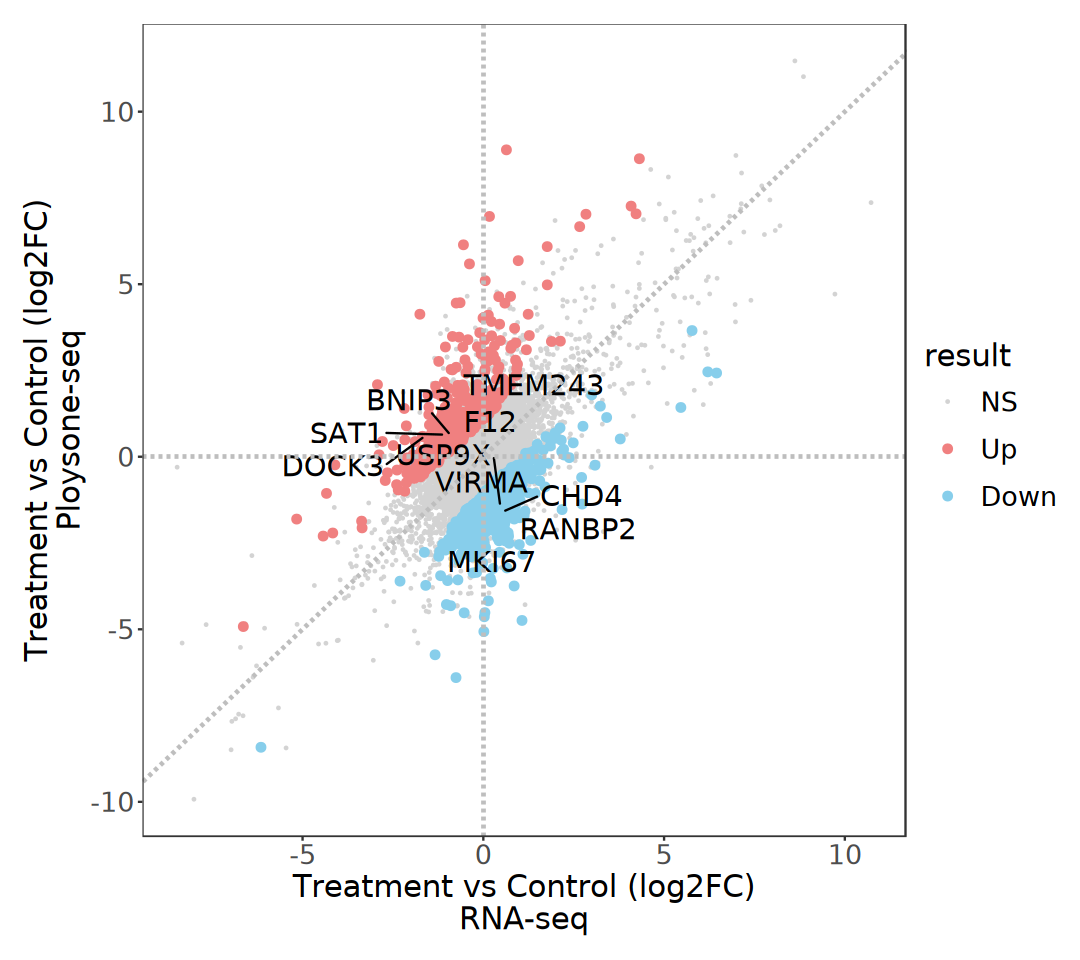

In [93]:
options(repr.plot.width = 9, repr.plot.height = 8)

# axisRange <- c(degs_result$log2FC_total, degs_result$log2FC_polysome) |> 
#     na.omit() %>% .[is.finite(.)] |> abs() |> max(na.rm = T) |> ceiling()

ggplot(degs_result, aes(x = log2FC_total, y = log2FC_polysome)) +
    geom_point(
        data = subset(degs_result, result == "NS"), 
        aes(color = result, size = result), na.rm = TRUE) + 
    geom_point(
        data = subset(degs_result, result != "NS"), 
        aes(color = result, size = result), na.rm = TRUE) + 
    geom_text_repel(
        aes(label = label),  na.rm = TRUE, size = 6, 
        color = "black", max.overlaps = Inf) +
    geom_hline(
        yintercept = 0, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    geom_vline(
        xintercept = 0, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    geom_abline(
        intercept = 0, slope = 1, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    # xlim(-axisRange, axisRange) + 
    # ylim(-axisRange, axisRange) + 
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "LightGray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 0.3))+
    labs(
        x = "Treatment vs Control (log2FC)\n RNA-seq ", 
        y = "Treatment vs Control (log2FC)\n Ploysone-seq ") + 
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Heatmap

In [94]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [95]:
ar <- degs_result |> 
    dplyr::select(DTEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Fraction, Group)

In [ ]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
fraction_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Fraction)),
    levels(eSet$Fraction))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- list(
    Group = group_colors, Fraction = fraction_colors, 
    Replicate = replicate_colors, DTEG = deg_colors, 
    logFC = colorRampPalette(brewer.pal(9, "PiYG"))(255) |> rev())

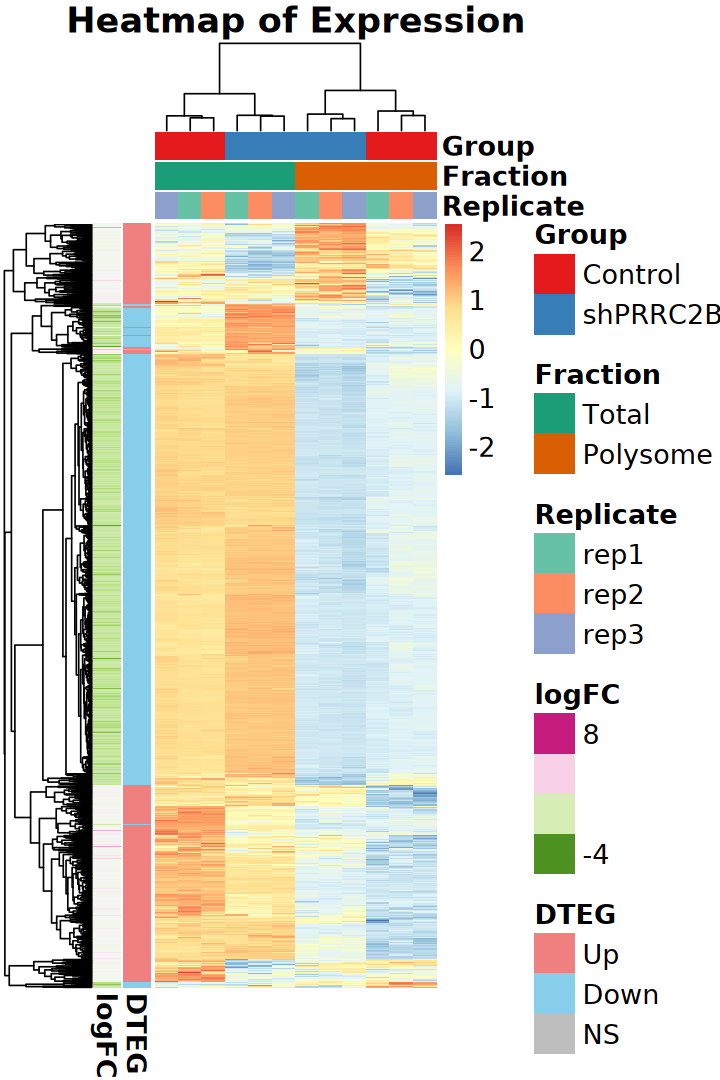

In [97]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors,
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

### ComplexHeatmap

In [98]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [99]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [100]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = brewer.pal(n = 11, name = "RdYlBu")[c(3,6,9)] |> rev())

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
fraction_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Fraction)),
    levels(eSet$Fraction))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [101]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Group, Fraction, Replicate)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Group = group_colors, 
        Fraction = fraction_colors,
        Replicate = replicate_colors))

In [102]:
ar <- degs_result |> 
    dplyr::select(logFC, DTEG = result) |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id")

anno_colors <- list(
    DTEG = deg_colors, 
    logFC = circlize::colorRamp2(
        breaks = c(-5, 0, 5),
        colors = rev(brewer.pal(n = 3, name = "PiYG"))))

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [103]:
right_anno <- rowAnnotation(
    foo = anno_mark(
        at = which(!is.na(degs_result$label)),
        labels = degs_result$symbol[which(!is.na(degs_result$label))],
        labels_gp = gpar(fontsize = 12)))

In [104]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)
lg_group <- Legend(
    title = "Group", labels = levels(dds$Group))
lg_fraction <- Legend(
    title = "Fraction", labels = levels(dds$Fraction))
lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))
lg_logfc <- Legend(
    title = "logFC", col_fun = anno_colors$logFC)
lg_deg <- Legend(
    labels = levels(degs_result$result), title = "DTEG", 
    legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_fraction, lg_replicate) |>
    packLegend(direction = "vertical")

In [105]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        show_row_names = FALSE, show_column_names = FALSE)

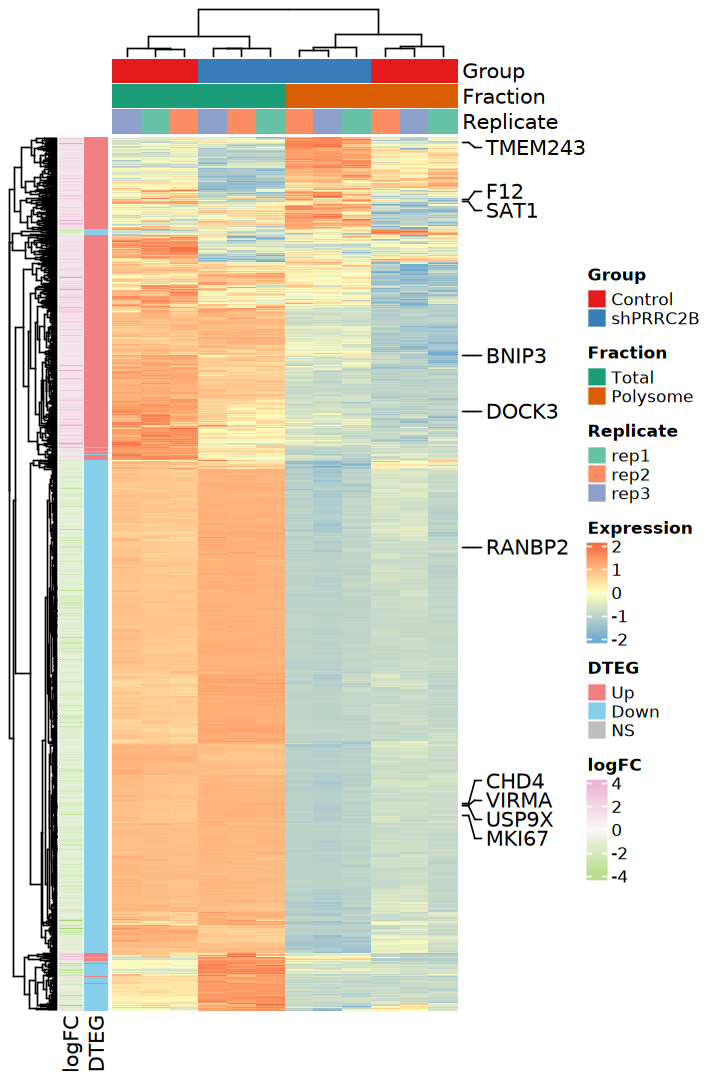

In [106]:
options(repr.plot.width = 6, repr.plot.height = 9)

draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_deg, lg_logfc), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 5), "mm"))

## 4). anota2seq

In [107]:
suppressPackageStartupMessages(library(anota2seq))

In [108]:
colData(eSet)

DataFrame with 12 rows and 4 columns
                              Cell    Group Fraction Replicate
                       <character> <factor> <factor>  <factor>
Control_total_rep1         HEK293T  Control Total         rep1
Control_total_rep2         HEK293T  Control Total         rep2
Control_total_rep3         HEK293T  Control Total         rep3
Control_polysome_rep1      HEK293T  Control Polysome      rep1
Control_polysome_rep2      HEK293T  Control Polysome      rep2
...                            ...      ...      ...       ...
shPRRC2B_total_rep2        HEK293T shPRRC2B Total         rep2
shPRRC2B_total_rep3        HEK293T shPRRC2B Total         rep3
shPRRC2B_polysome_rep1     HEK293T shPRRC2B Polysome      rep1
shPRRC2B_polysome_rep2     HEK293T shPRRC2B Polysome      rep2
shPRRC2B_polysome_rep3     HEK293T shPRRC2B Polysome      rep3

In [109]:
ads <- anota2seqDataSetFromMatrix(
    dataP = assay(eSet[, eSet$Fraction == "Polysome"], "counts"),
    dataT = assay(eSet[, eSet$Fraction == "Total"], "counts"),
    phenoVec = rep(c("Control", "shPRRC2B"), each = 3),
    dataType = "RNAseq", normalize = TRUE)

ads

Removing zero count genes from data ...


1282  genes were removed due to having 0 counts in at least one sample.




Count data will be normalized and transformed according to the TMM-log2 method.


All input checkpoints passed.




Information on input data.
dataP and dataT contain data for 12688 mRNA and 6 samples. 

Your sample classes are:
 	 Control shPRRC2B 


No custom contrasts set, default will be used.
No differential expression analysis for translated mRNA has been detected.
No differential expression analysis for total mRNA has been detected.
No analysis of translation has been detected.
No analysis of buffering has been detected.
No selected data of differential expression analysis for translated mRNA has been detected.
No selected data of differential expression analysis for total mRNA has been detected.
No selected data of analysis of translation has been detected.
No selected data of analysis of buffering has been detected.

No output for mRNA abundance genes.

In [110]:
# ~ 3 min
ads <- anota2seqRun(ads)
ads

Running anota2seqPerformQc quality control


	Calculating omnibus interactions & effects and dfbetas




  |======================================================================| 100%





	Assessing dfbetas for model without interaction


	Performing dfbetas simulation




  |======================================================================| 100%





	Using RVM for omnibus interaction statistics


	The a and b parameters for the inverse gamma distribution are:
	a:1.62533162222731 b:5.81296459609306


	Using RVM for omnibus group statistics


	The a and b parameters for the inverse gamma distribution are:
	a:1.57230190176457 b:6.31073467587964


	Adjusting p-values for multiple testing



Running anota2seqResidOutlierTest




  |======================================================================| 100%

... (10 outputs left out)

         contrast 1
Control          -1
shPRRC2B          1


  |======================================================================| 100%





	Calculating RVM statistics


	Assessing contrast1


	The a and b parameters for the inverse gamma distribution are:
	a:0.943854846055944 b:61.0018547312489


End of analysis of translational buffering.


Start filtering for significant genes ... 


Your filtering parameters are:


minSlopeTranslation:  -1 


maxSlopeTranslation:  2 


minSlopeBuffering:  -2 


maxSlopeBuffering:  1 


maxPAdj:  0.15 


maxP:   


minEff:   


deltaPT:  0.263034405833794 


deltaTP:  0.263034405833794 


deltaP:   


deltaT:   





Starting filtering of: translated mRNA


	filtering contrast 1.


	Contrast 1 done.


Filtering for analysis translated mRNA done.


Starting filtering of: total mRNA


	filtering contrast 1.


	Contrast 1 done.


Filtering for analysis total mRNA done.


Starting filtering of: translation


	filtering contrast 1.


Warning message in anota2seqSelSigGenes(Anota2seqDataSet, selContrast = c(1:dim(contrasts)[2]), :
“No genes pass selected thresholds for analysis of transla

Information on input data.
dataP and dataT contain data for 12688 mRNA and 6 samples. 

Your sample classes are:
 	 Control shPRRC2B 

contrasts used in the analysis are:
			 shPRRC2B 
	 Control 		 -1 	
	 shPRRC2B 		 1 	


Output for differential expression analysis of translated mRNA detected.

Output for differential expression analysis of total mRNA detected.

Output for analysis of translation detected.

Output for analysis of buffering detected.

Output for differential expression analysis of translated mRNA detected:
Selected output of translated mRNA contains:
	for contrast 1 
		Total: 4837 genes.
		Positive log2FC: 2295 genes.
		Negative log2FC: 2542 genes.

Output for differential expression analysis of total mRNA detected:
Selected output of total mRNA contains:
	for contrast 1 
		Total: 9122 genes.
		Positive log2FC: 4961 genes.
		Negative log2FC: 4161 genes.

Output for analysis of translation detected:
Selected output of translation contains:
	for contrast 1 
		Total: 0 ge

Creating Fold-change plots.




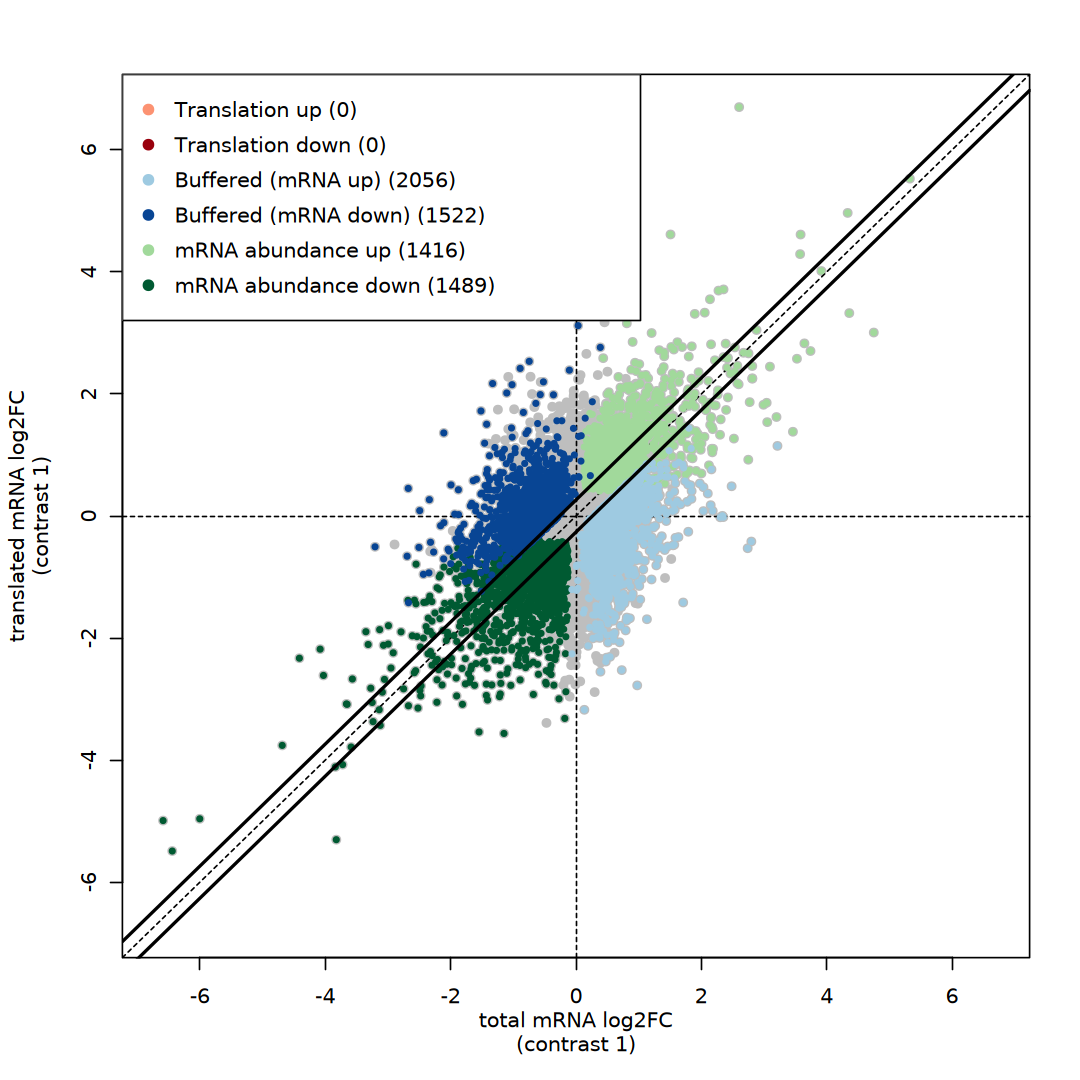

In [111]:
options(repr.plot.width = 9, repr.plot.height = 9)
anota2seqPlotFC(ads, selContrast = 1, plotToFile = FALSE)

In [112]:
ads_res <- anota2seqGetOutput(
    ads, analysis = "translation", output = "full", 
    getRVM = TRUE, selContrast = 1)

head(ads_res)

,apvSlope,apvSlopeP,apvEff,apvRvmMSerror,apvRvmF,residRvmDf,apvRvmP,apvRvmPAdj
ENSG00000187634.13,0.22275546,1.00000000,0.6764134,0.0838425,5.457078,4.501093,0.07245756,0.4520054
ENSG00000188976.11,-2.70051606,0.19935234,3.1385972,6.0530904,1.627399,4.501093,0.26392606,0.6237642
ENSG00000187961.15,-0.07891295,0.45213865,0.4814089,0.1237255,1.873135,4.501093,0.23545905,0.6044385
ENSG00000188290.11,1.35255634,0.33420923,1.7115386,0.2022862,14.481286,4.501093,0.01528489,0.3860443
ENSG00000187608.10,0.08944431,1.00000000,0.5597348,0.1865030,1.679882,4.501093,0.25740911,0.6200886
ENSG00000188157.16,-2.01042566,0.06219852,-1.7257274,0.2339679,12.728821,4.501093,0.01920814,0.3897217


# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)